# Seasonal to decadal changes in supra-permafrost soil and aquifer thermal hydrology: broader, deeper, and longer activity. 
## MDA

This notebook combines model validation and post-processing analyses for the Advanced Terrestrial Simulator (ATS) simulations of Imnavait Creek, Alaska

- **Sim 1 (1981–2020):** `run_04_transect_transient_1981-2020`
- **Sim 2 (2019–2024):** `run_04_transect_transient_2019-2024`

The two runs are spliced at **2020-01-01**: Sim 1 data are used up to 2019-12-31, Sim 2 data from 2020-01-01 onward.

### Sections
1. Imports & Helper Functions
2. Load Meteorological Forcing Data (ABoVE DAAC)
3. Climate Forcing Analysis (1981–2024)
4. Load Column & Transect Model Output
5. Model Validation — Snow Depth & Soil Temperature
6. Model Validation — Water Table & Ice Table Depth
7. Zero-Curtain Duration Analysis
8. Active Layer (Unfrozen Area) Time Series
9. Maximum Thaw Depth Analysis
10. Net Runoff Trends
11. Domain-Averaged Enthalpy Analysis
12. Velocity Field Visualization

## 1. Imports & Helper Functions

In [1]:
%matplotlib inline

import os
import sys
import calendar
import math
import glob
from datetime import datetime, timedelta
from itertools import islice

import numpy as np
import pandas as pd
import h5py
import scipy.io as sio
import netCDF4
import xarray as xr
from pyproj import Transformer, Proj
from scipy.interpolate import griddata, CubicSpline
from scipy.io import loadmat
from scipy.ndimage import uniform_filter1d
from scipy.stats import lognorm, theilslopes, kendalltau
from scipy.optimize import minimize
from scipy import stats
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression, RANSACRegressor
from sklearn.preprocessing import PolynomialFeatures

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import matplotlib.colorbar as colorbar
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
from matplotlib.collections import PolyCollection
from matplotlib.cm import ScalarMappable
from matplotlib.gridspec import GridSpec
from matplotlib.colorbar import ColorbarBase
from matplotlib.patches import Patch
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.mplot3d import Axes3D
import seaborn as sns
from tqdm.notebook import tqdm
import imageio
import cv2
import pymannkendall as mk

from modvis import ATSutils, utils
import modvis.general_plots as gp
import modvis.colors as modvis_colors   # renamed to avoid clobbering mcolors

# ATS-specific tools
sys.path.append('/home/nm32873/ATS/ats-1.6-dev-414f81aa/repos/amanzi/src/physics/ats/tools/utils')
sys.path.append('/home/nm32873/ATS/ats-1.6-dev-414f81aa/repos/amanzi/src/physics/atsDIR/docs/documentation/source/ats_demos')
import ats_xdmf
import plot_column_data
import colors  # ATS color utilities (ice, water, gas colormaps)

mpl.rcParams['figure.dpi'] = 100
mpl.rcParams['savefig.dpi'] = 300

In [3]:
from utils.data_io   import plot_h5_data, get_temp_profile
from utils.mesh_utils import get_cell_areas, filter_paths, extract_data_for_paths
from utils.analysis  import (theil_sen_fit, determine_ice_table_depth,
                              build_ice_table_df, compute_winter_temp,
                              compute_winter_snow, compute_ponded_depth_series,
                              compute_unfrozen_area_series)
from utils.plotting  import plot_zc_duration

## 2. Load Meteorological Forcing Data (ABoVE DAAC)

Two HDF5 files provide daily meteorological forcing (air temperature, precipitation as rain/snow, snow density) derived from the NASA ABoVE SnowModel product:
- `forcing_daac_ABoVE_snowmodel_1981_2020.h5` — covers 1981-01-01 to 2020-08-31
- `forcing_daac_ABoVE_snowmodel_2019_2024.h5` — covers 2019-01-01 to 2024 (length auto-detected)

In [5]:
# ── Sim 1 forcing: 1981–2020 ──────────────────────────────────────────────────
dates1 = pd.date_range(start='1981-01-01', end='2020-08-31', freq='D')
forcing1 = "../data/forcing_daac_ABoVE_snowmodel_1981_2020.h5"
stats_fr1, data_fr1, time_fr1 = plot_h5_data(forcing1)
df_forcing1 = pd.DataFrame(data_fr1)
df_forcing1['Date'] = dates1
df_forcing1['air temperature [C]'] = df_forcing1['air temperature [K]'] - 273.15
df_forcing1['Year'] = df_forcing1['Date'].dt.year
df_forcing1['Date'] = pd.to_datetime(df_forcing1['Date'])
df_forcing1.set_index('Date', inplace=True)

# ── Sim 2 forcing: 2019–2024 ──────────────────────────────────────────────────
forcing2 = "../data/forcing_daac_ABoVE_snowmodel_2019_2024.h5"
stats_fr2, data_fr2, time_fr2 = plot_h5_data(forcing2)
df_forcing2 = pd.DataFrame(data_fr2)
n_rows2 = len(df_forcing2)
dates2_forcing = pd.date_range(start='2019-01-01', periods=n_rows2, freq='D')
print(f"Sim2 forcing date range: {dates2_forcing[0].date()} → {dates2_forcing[-1].date()}  ({n_rows2} days)")
df_forcing2['Date'] = dates2_forcing
df_forcing2['air temperature [C]'] = df_forcing2['air temperature [K]'] - 273.15
df_forcing2['Year'] = df_forcing2['Date'].dt.year
df_forcing2['Date'] = pd.to_datetime(df_forcing2['Date'])
df_forcing2.set_index('Date', inplace=True)

# ── Combined forcing: splice at 2020-01-01 ────────────────────────────────────
df_combined = pd.concat([
    df_forcing1[df_forcing1.index < '2020-01-01'],
    df_forcing2[df_forcing2.index >= '2020-01-01']
]).sort_index()
print(f"Combined forcing: {df_combined.index[0].date()} → {df_combined.index[-1].date()}")
# Splice date between the two simulation periods
CUTOFF_DATE = datetime(2020, 1, 1)


Sim2 forcing date range: 2019-01-01 → 2024-12-29  (2190 days)
Combined forcing: 1981-01-01 → 2024-12-29


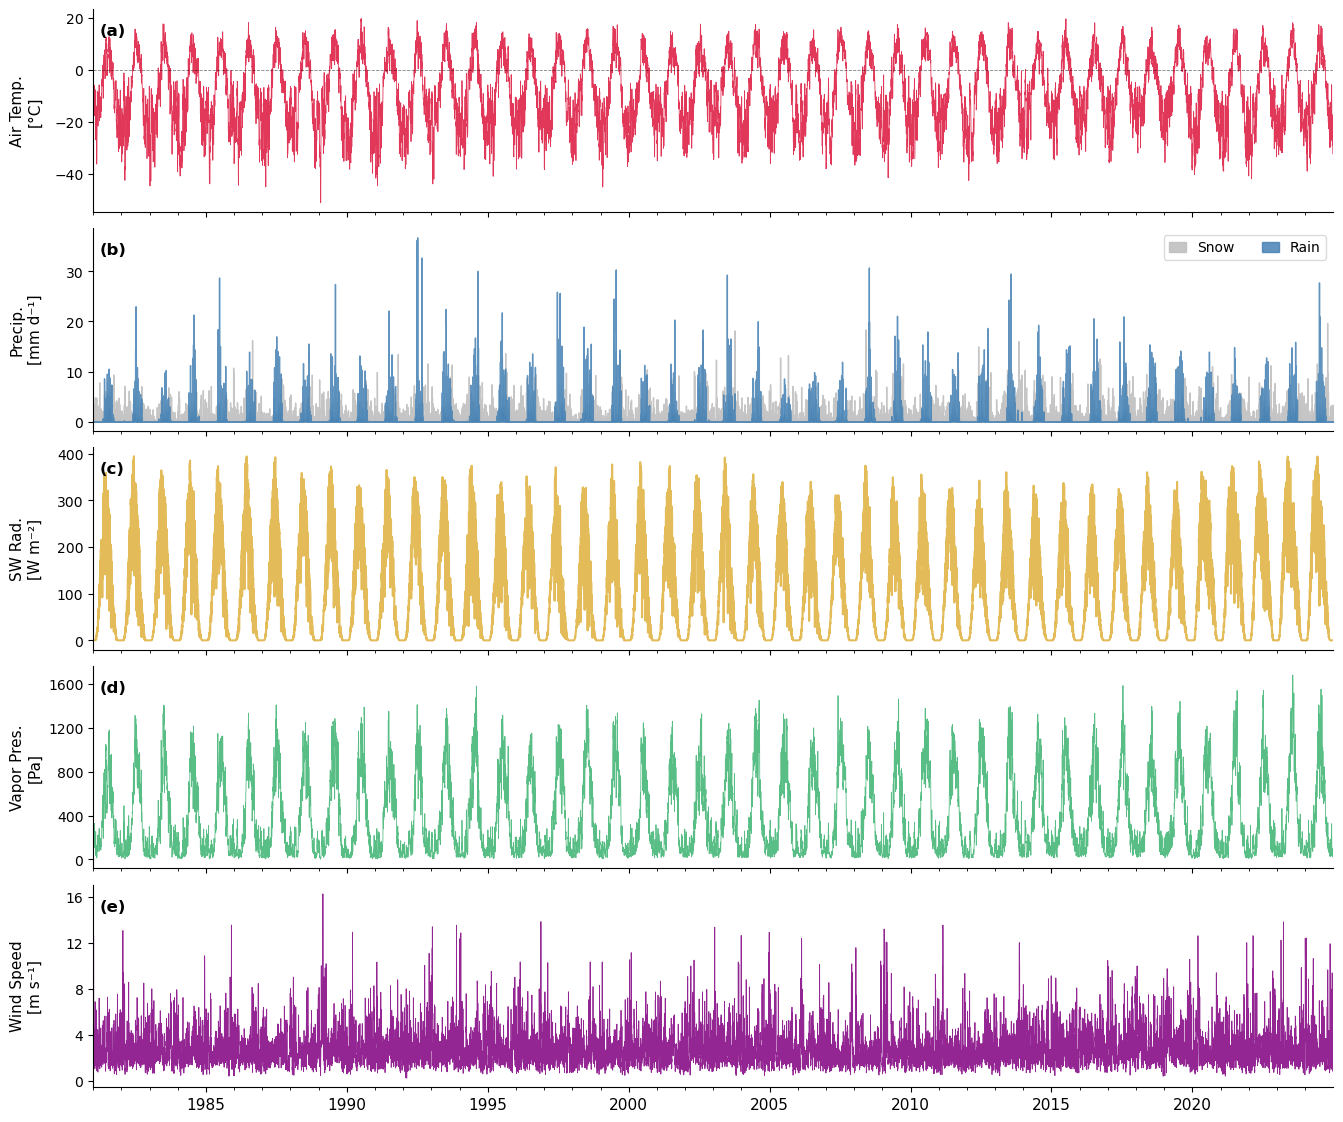

In [7]:
# ── Meteorological Forcing Overview ──────────────────────────────────────────
# df_combined: daily DatetimeIndex, 1981–2024
# Precipitation converted from m s⁻¹ → mm d⁻¹

# ── Unit conversion ───────────────────────────────────────────────────────────
S_PER_DAY = 86_400
M_TO_MM   = 1_000

rain_mm  = df_combined["Precipitation Rain [m s^-1]"]* S_PER_DAY * M_TO_MM
snow_mm  = df_combined["Precipitation Snow [m SWE s^-1]"]* S_PER_DAY * M_TO_MM
tair     = df_combined["air temperature [C]"]
sw       = df_combined["incoming shortwave radiation [W m^-2]"]
vp       = df_combined["vapor pressure air [Pa]"]
wind     = df_combined["wind speed [m s^-1]"]

dates = df_combined.index

# ── Figure layout ─────────────────────────────────────────────────────────────
fig, axes = plt.subplots(
    5, 1,
    figsize=(16, 14),
    sharex=True,
    gridspec_kw={"hspace": 0.08},
)

ax_t, ax_p, ax_sw, ax_vp, ax_ws = axes

# ── 1. Air Temperature ────────────────────────────────────────────────────────
ax_t.plot(dates, tair, color="crimson", linewidth=0.6, alpha=0.85)
ax_t.axhline(0, color="k", linewidth=0.6, linestyle="--", alpha=0.5)
ax_t.set_ylabel("Air Temp.\n[°C]", fontsize=11)
ax_t.yaxis.set_major_locator(mticker.MaxNLocator(5, prune="both"))

# ── 2. Precipitation (rain + snow) ────────────────────────────────────────────
ax_p.fill_between(dates, snow_mm, step="mid", color="silver",
                  alpha=0.9, label="Snow")
ax_p.fill_between(dates, rain_mm, step="mid", color="steelblue",
                  alpha=0.85, label="Rain")
ax_p.set_ylabel("Precip.\n[mm d⁻¹]", fontsize=11)
ax_p.yaxis.set_major_locator(mticker.MaxNLocator(5, prune="both"))
ax_p.legend(loc="upper right", fontsize=10, framealpha=0.7,
            ncol=2, handlelength=1.2)

# ── 3. Incoming Shortwave Radiation ───────────────────────────────────────────
ax_sw.plot(dates, sw, color="goldenrod", alpha=0.75)
ax_sw.set_ylabel("SW Rad.\n[W m⁻²]", fontsize=11)
ax_sw.yaxis.set_major_locator(mticker.MaxNLocator(5, prune="both"))

# ── 4. Vapor Pressure ─────────────────────────────────────────────────────────
ax_vp.plot(dates, vp, color="mediumseagreen", linewidth=0.6, alpha=0.85)
ax_vp.set_ylabel("Vapor Pres.\n[Pa]", fontsize=11)
ax_vp.yaxis.set_major_locator(mticker.MaxNLocator(5, prune="both"))

# ── 5. Wind Speed ─────────────────────────────────────────────────────────────
ax_ws.plot(dates, wind, color="purple", linewidth=0.6, alpha=0.85)
ax_ws.set_ylabel("Wind Speed\n[m s⁻¹]", fontsize=11)
ax_ws.yaxis.set_major_locator(mticker.MaxNLocator(5, prune="both"))

# ── Shared x-axis formatting ──────────────────────────────────────────────────
ax_ws.xaxis.set_major_locator(mdates.YearLocator(5))
ax_ws.xaxis.set_minor_locator(mdates.YearLocator(1))
ax_ws.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax_ws.set_xlim(dates[0], dates[-1])
plt.setp(ax_ws.get_xticklabels(), rotation=0, ha="center", fontsize=11)

# ── Panel labels (a–e) ────────────────────────────────────────────────────────
for ax, label in zip(axes, list("abcde")):
    ax.text(0.005, 0.93, f"({label})", transform=ax.transAxes,
            fontsize=12, fontweight="bold", va="top")
    ax.tick_params(axis="y", labelsize=10)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

fig.align_ylabels(axes)
plt.show()

## 3. Climate Forcing Analysis (1981–2024)

### 3a. Air Temperature Trends: Summer (JJA) and Winter (Non-JJA)

Theil–Sen slopes (robust linear regression) and Mann–Kendall p-values are computed for summer, winter, and annual mean air temperatures.

Summer  trend : +0.182 °C/decade  |  Δ+0.78 °C over 43 yr  |  MK τ=0.156, p=0.1344
Winter  trend : +0.456 °C/decade  |  Δ+1.96 °C over 43 yr  |  MK τ=0.245, p=0.0190
Annual  trend : +0.358 °C/decade  |  Δ+1.54 °C over 43 yr  |  MK τ=0.281, p=0.0071


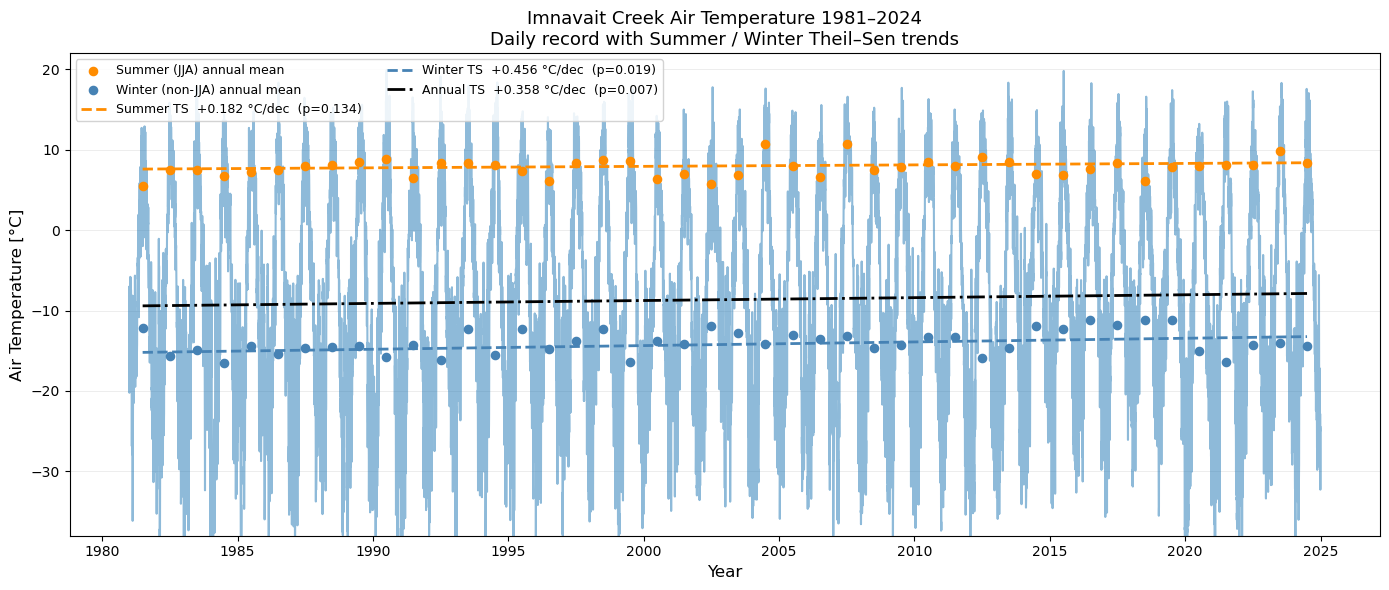

In [8]:
col = 'air temperature [C]'

df_summer = df_combined[df_combined.index.month.isin([6, 7, 8])]
df_winter = df_combined[~df_combined.index.month.isin([6, 7, 8])]

summer_avg = df_summer.groupby(df_summer.index.year)[col].mean().loc[1981:2024]
winter_avg = df_winter.groupby(df_winter.index.year)[col].mean().loc[1981:2024]
annual_avg = df_combined.groupby(df_combined.index.year)[col].mean().loc[1981:2024]

common_years = sorted(set(summer_avg.index) & set(winter_avg.index) & set(annual_avg.index))
summer_avg = summer_avg.loc[common_years]
winter_avg = winter_avg.loc[common_years]
annual_avg = annual_avg.loc[common_years]
years = np.array(common_years)

sl_s, ic_s, fit_s, tau_s, p_s = theil_sen_fit(summer_avg.values, years)
sl_w, ic_w, fit_w, tau_w, p_w = theil_sen_fit(winter_avg.values, years)
sl_a, ic_a, fit_a, tau_a, p_a = theil_sen_fit(annual_avg.values, years)
n_years = years[-1] - years[0]
print(f"Summer  trend : {sl_s*10:+.3f} °C/decade  |  Δ{sl_s*n_years:+.2f} °C over {n_years} yr  |  MK τ={tau_s:.3f}, p={p_s:.4f}")
print(f"Winter  trend : {sl_w*10:+.3f} °C/decade  |  Δ{sl_w*n_years:+.2f} °C over {n_years} yr  |  MK τ={tau_w:.3f}, p={p_w:.4f}")
print(f"Annual  trend : {sl_a*10:+.3f} °C/decade  |  Δ{sl_a*n_years:+.2f} °C over {n_years} yr  |  MK τ={tau_a:.3f}, p={p_a:.4f}")

year_dates = pd.to_datetime([f'{y}-07-01' for y in years])

fig, ax = plt.subplots(figsize=(14, 6))
ax.plot(df_combined.index, df_combined[col], alpha=0.5)
ax.scatter(year_dates, summer_avg.values, color='darkorange', s=35, zorder=4, label='Summer (JJA) annual mean')
ax.scatter(year_dates, winter_avg.values, color='steelblue', s=35, zorder=4, label='Winter (non-JJA) annual mean')
ax.plot(year_dates, fit_s, color='darkorange', lw=2, ls='--',
        label=f'Summer TS  {sl_s*10:+.3f} °C/dec  (p={p_s:.3f})')
ax.plot(year_dates, fit_w, color='steelblue',  lw=2, ls='--',
        label=f'Winter TS  {sl_w*10:+.3f} °C/dec  (p={p_w:.3f})')
ax.plot(year_dates, fit_a, color='black', lw=2, ls='-.',
        label=f'Annual TS  {sl_a*10:+.3f} °C/dec  (p={p_a:.3f})')
ax.set_ylim(-38, 22)
ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Air Temperature [°C]', fontsize=12)
ax.set_title('Imnavait Creek Air Temperature 1981–2024\nDaily record with Summer / Winter Theil–Sen trends', fontsize=13)
ax.legend(fontsize=9, loc='upper left', ncol=2, framealpha=0.85)
ax.grid(axis='y', lw=0.4, alpha=0.4)
plt.tight_layout()
plt.show()

### 3b. Monthly Mean Air Temperature Heatmap (1981–2024)

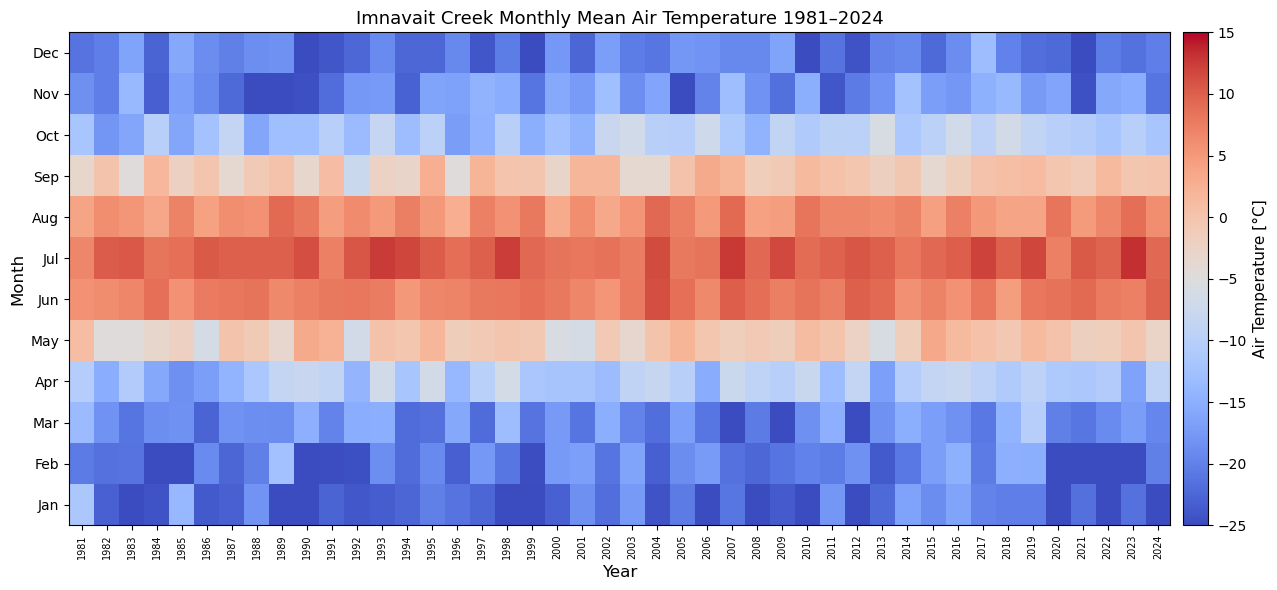

In [9]:
monthly_avg = df_combined[col].resample('ME').mean()
monthly_avg_df = monthly_avg.to_frame()
monthly_avg_df['Year']  = monthly_avg_df.index.year
monthly_avg_df['Month'] = monthly_avg_df.index.month
heatmap_data = monthly_avg_df.pivot(index='Month', columns='Year', values=col)

fig, ax = plt.subplots(figsize=(14, 6))
im = ax.imshow(heatmap_data.values, aspect='auto', cmap='coolwarm',
               origin='lower', vmin=-25, vmax=15)
cbar = plt.colorbar(im, ax=ax, pad=0.01)
cbar.set_label('Air Temperature [°C]', fontsize=11)
ax.set_xticks(np.arange(len(heatmap_data.columns)))
ax.set_xticklabels(heatmap_data.columns, rotation=90, fontsize=7)
ax.set_yticks(np.arange(12))
ax.set_yticklabels(['Jan','Feb','Mar','Apr','May','Jun',
                    'Jul','Aug','Sep','Oct','Nov','Dec'], fontsize=10)
ax.set_title('Imnavait Creek Monthly Mean Air Temperature 1981–2024', fontsize=13)
ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Month', fontsize=12)
plt.tight_layout()
plt.show()

### 3c. Yearly Cumulative Snowfall (1981–2024)

/tmp/ipykernel_1880699/758425285.py:1: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  yearly_snow_avg = (df_combined['Precipitation Snow [m SWE s^-1]'] * 86400 * 1000).resample('Y').sum()


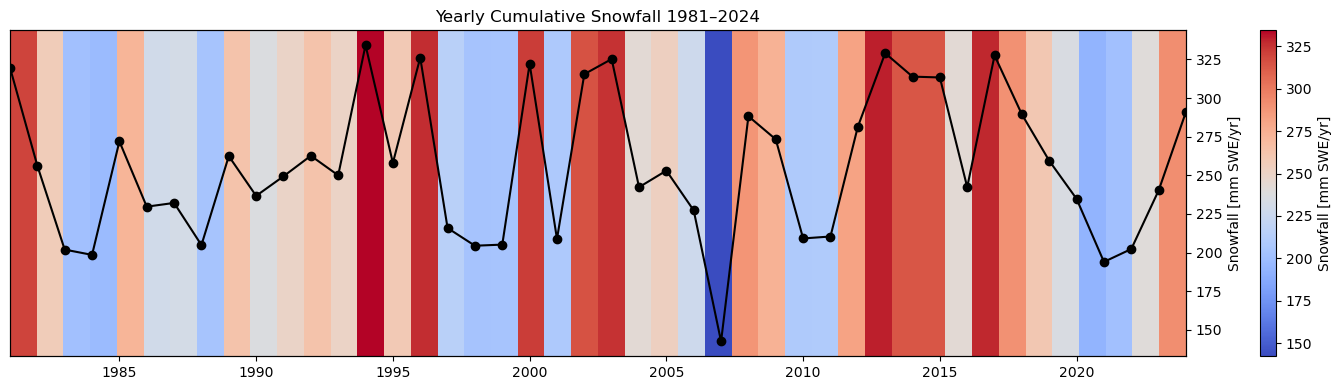

In [10]:
yearly_snow_avg = (df_combined['Precipitation Snow [m SWE s^-1]'] * 86400 * 1000).resample('Y').sum()
yrs_snow = yearly_snow_avg.index.year
snow = yearly_snow_avg.values

fig, ax1 = plt.subplots(figsize=(15, 4))
ax1.imshow(snow.reshape(1, -1), aspect='auto', cmap='coolwarm',
           extent=[yrs_snow[0], yrs_snow[-1], 0, 1],
           vmin=snow.min(), vmax=snow.max())
ax1.set_yticks([])
ax1.set_xlim(yrs_snow[0], yrs_snow[-1])
ax1.set_title('Yearly Cumulative Snowfall 1981–2024')
cbar = plt.colorbar(ax1.images[0], ax=ax1, orientation='vertical')
cbar.set_label('Snowfall [mm SWE/yr]')
ax2 = ax1.twinx()
ax2.plot(yrs_snow, snow, marker='o', linestyle='-', color='black')
ax2.set_ylabel('Snowfall [mm SWE/yr]')
ax2.grid(False)
plt.tight_layout()
plt.show()

## 4. Load Column & Transect Model Output

### 4a. Column (1D) Model Directories and Observation Files

Column model results are used for snow depth and soil temperature validation against SNOTEL data.

In [ ]:
# ── Column run directories ────────────────────────────────────────────────────
# These are the two best-fit parameter sets chosen after calibration.
rundir  = "../runs/run03_column_transient_calibration_SnowExp_0p24_swe*1p0_2011-2020"
rundir2 = "../runs/run03_column_transient_calibration_SnowExp_0p26_swe*1p0_2019-2024"

# ── Load column observation DAT files ─────────────────────────────────────────
runobs = pd.read_csv(rundir + "/observation_columnSpinup.dat", comment='#')
runobs['Date'] = pd.date_range(start='2011-01-01', periods=len(runobs), freq='D')
runobs['DOY']  = runobs['Date'].dt.dayofyear
# Skip first 2 years (model spin-up period)
runobs = runobs[runobs['Date'] >= '2013-01-01'].copy()

runobs2 = pd.read_csv(rundir2 + "/observation_columnSpinup.dat", comment='#')
runobs2_dates = pd.date_range(start='2019-01-01', periods=len(runobs2), freq='D')
runobs2['Date'] = runobs2_dates
runobs2['DOY']  = runobs2['Date'].dt.dayofyear
runobs2_single = runobs2.groupby('time [d]').mean().reset_index()
runobs2_single['Date'] = pd.date_range(start='2019-01-01', periods=len(runobs2_single), freq='D')
runobs2_single['DOY']  = runobs2_single['Date'].dt.dayofyear
runobs2_single = runobs2_single[runobs2_single['Date'] >= '2021-01-01']

# ── SNOTEL observation files ──────────────────────────────────────────────────
st_sd = pd.read_csv('../../data/SNOWTEL_snowdepth2011_2025.txt', comment='#')
st_sd['Date'] = pd.to_datetime(st_sd['Date'])
st_sd['snowdepth [m]'] = st_sd['Snow Depth (in) Start of Day Values'] * 0.0254
st_sd['DOY'] = st_sd['Date'].dt.dayofyear

st_soitmp = pd.read_csv('../../data/SNOWTEL_soiltemp2011_2025.txt', comment='#')
st_soitmp['Date'] = pd.to_datetime(st_soitmp['Date'])
st_soitmp['soilTempC'] = (st_soitmp['Soil Temperature Observed -2in (degF) Start of Day Values'] - 32) * 5 / 9
st_soitmp['DOY'] = st_soitmp['Date'].dt.dayofyear

print("Column obs loaded. SNOTEL obs loaded.")


Column obs loaded. SNOTEL obs loaded.


### 4b. Transect (2D) Model Directories and VisFile Objects

The transect simulations use 2D cross-section meshes. Both the surface and subsurface VisFiles are loaded here. The simulation cutoff date determines which VisFile is used for each analysis.

In [ ]:
# ── Transect run directories ──────────────────────────────────────────────────
rundir_transect_1981_2020 = "../runs/run_04_transect_transient_1981-2020"
rundir_transect_2019_2024 = "../runs/run_04_transect_transient_2019-2024"

CUTOFF_DATE = datetime(2020, 1, 1)

# ── Load VisFile objects ───────────────────────────────────────────────────────
vis_surf_1981_2020 = ats_xdmf.VisFile(rundir_transect_1981_2020, domain='surface', time_unit='d')
vis_surf_1981_2020.filterIndices(range(0, len(vis_surf_1981_2020.times), 1))
vis_surf_1981_2020.loadMesh(order=['x', 'z'])

vis_1981_2020 = ats_xdmf.VisFile(rundir_transect_1981_2020, time_unit='d')
vis_1981_2020.filterIndices(range(0, len(vis_1981_2020.times), 1))
vis_1981_2020.loadMeshPolygons()

vis_surf_2019_2024 = ats_xdmf.VisFile(rundir_transect_2019_2024, domain='surface', time_unit='d')
vis_surf_2019_2024.filterIndices(range(0, len(vis_surf_2019_2024.times), 1))
vis_surf_2019_2024.loadMesh(order=['x', 'z'])

vis_2019_2024 = ats_xdmf.VisFile(rundir_transect_2019_2024, time_unit='d')
vis_2019_2024.filterIndices(range(0, len(vis_2019_2024.times), 1))
vis_2019_2024.loadMeshPolygons()

# ── Derive simulation epochs from known start dates ───────────────────────────
# epoch = calendar date of day 0 in the simulation time axis
SIM_1981_START = datetime(1981, 1, 1)
SIM_2019_START = datetime(2019, 1, 1)
EPOCH_1981 = SIM_1981_START - timedelta(days=int(vis_1981_2020.times[0]))
EPOCH_2019 = SIM_2019_START - timedelta(days=int(vis_2019_2024.times[0]))

print(f"Sim1 spans: {EPOCH_1981 + timedelta(days=int(vis_1981_2020.times[0]))} → "
      f"{EPOCH_1981 + timedelta(days=int(vis_1981_2020.times[-1]))}")
print(f"Sim2 spans: {EPOCH_2019 + timedelta(days=int(vis_2019_2024.times[0]))} → "
      f"{EPOCH_2019 + timedelta(days=int(vis_2019_2024.times[-1]))}")

# ── Reference elevation profile (time-independent) ───────────────────────────
elev = vis_surf_2019_2024.get('surface-elevation', vis_surf_2019_2024.cycles[1])

# ── Cell areas (Shoelace formula) ─────────────────────────────────────────────
cell_areas_sim1 = get_cell_areas(vis_1981_2020)
cell_areas_sim2 = get_cell_areas(vis_2019_2024)
print(f"Sim1: {len(cell_areas_sim1)} cells, total area = {cell_areas_sim1.sum():.2f} m²")
print(f"Sim2: {len(cell_areas_sim2)} cells, total area = {cell_areas_sim2.sum():.2f} m²")

Sim1 spans: 1981-01-01 00:00:00 → 2020-08-31 00:00:00
Sim2 spans: 2019-01-01 00:00:00 → 2024-12-30 00:00:00
Sim1: 20088 cells, total area = 4360.00 m²
Sim2: 20088 cells, total area = 4360.00 m²


### 4c. Load Transect Observation DAT Files

In [18]:
# ── Load 2D observation files (spatially-averaged outputs) ───────────────────
runobs_transect_1981_2020 = pd.read_csv(rundir_transect_1981_2020 + "/observation_2D.dat", comment='#')
dates_transect = pd.date_range(start='1981-01-01', periods=len(runobs_transect_1981_2020), freq='D')
assert len(dates_transect) == len(runobs_transect_1981_2020), "Date range length mismatch (1981–2020)"
runobs_transect_1981_2020['Date'] = dates_transect
runobs_transect_1981_2020['DOY'] = runobs_transect_1981_2020['Date'].dt.dayofyear

runobs_transect_2019_2024 = pd.read_csv(rundir_transect_2019_2024 + "/observation_2D.dat", comment='#')
dates_transect_2 = pd.date_range(start='2019-01-01', periods=len(runobs_transect_2019_2024), freq='D')
assert len(dates_transect_2) == len(runobs_transect_2019_2024), "Date range length mismatch (2019–2024)"
runobs_transect_2019_2024['Date'] = dates_transect_2
runobs_transect_2019_2024['DOY'] = runobs_transect_2019_2024['Date'].dt.dayofyear

# ── Splice at 2020-01-01 ──────────────────────────────────────────────────────
runobs_1981_2019 = runobs_transect_1981_2020[runobs_transect_1981_2020['Date'] <= '2019-12-31'].copy()
runobs_2020_2024 = runobs_transect_2019_2024[runobs_transect_2019_2024['Date'] >= '2020-01-01'].copy()
runobs_transect_1981_2024 = pd.concat([runobs_1981_2019, runobs_2020_2024], ignore_index=True)
runobs_transect_1981_2024['Date'] = pd.to_datetime(runobs_transect_1981_2024['Date'])

print(f"Combined transect obs: {runobs_transect_1981_2024['Date'].iloc[0].date()} → "
      f"{runobs_transect_1981_2024['Date'].iloc[-1].date()}  "
      f"({len(runobs_transect_1981_2024)} rows)")

Combined transect obs: 1981-01-01 → 2024-12-30  (16070 rows)


## 5. Model Validation — Snow Depth & Soil Temperature

Simulated snow depth and shallow soil temperature (5 cm depth) are compared against SNOTEL station observations. Day-of-year (DOY) mean and ±1 SD envelopes are shown for both 2011–2020 and 2019–2024 simulations combined.

In [19]:
# ── Compute DOY statistics for model snow depth & surface temperature ─────────

model_sd_mean = runobs.groupby('DOY')['snow depth [m]'].mean()
model_sd_std  = runobs.groupby('DOY')['snow depth [m]'].std()
model_st_mean = runobs.groupby('DOY')['surface temperature [K]'].mean() - 273.15
model_st_std  = runobs.groupby('DOY')['surface temperature [K]'].std()

model_sd_mean2 = runobs2_single.groupby('DOY')['snow depth [m]'].mean()
model_sd_std2  = runobs2_single.groupby('DOY')['snow depth [m]'].std()
model_st_mean2 = runobs2_single.groupby('DOY')['surface temperature [K]'].mean() - 273.15
model_st_std2  = runobs2_single.groupby('DOY')['surface temperature [K]'].std()

# ── Combine both runs by DOY ───────────────────────────────────────────────────
runobs_combined = pd.concat([runobs, runobs2_single], ignore_index=True)
model_sd_mean_comb = runobs_combined.groupby('DOY')['snow depth [m]'].mean()
model_sd_std_comb  = runobs_combined.groupby('DOY')['snow depth [m]'].std()
model_st_mean_comb = runobs_combined.groupby('DOY')['surface temperature [K]'].mean() - 273.15
model_st_std_comb  = runobs_combined.groupby('DOY')['surface temperature [K]'].std()

# ── Soil temperature at 5 cm depth from temperature profile ──────────────────
times_col,  z_col,  temp_col  = get_temp_profile(rundir)
times_col2, z_col2, temp_col2 = get_temp_profile(rundir2)

z_target = -0.05   # 5 cm below surface
depth_idx  = np.argmin(np.abs((z_col  - z_col[-1])  - z_target))
depth_idx2 = np.argmin(np.abs((z_col2 - z_col2[-1]) - z_target))

# Epoch offsets so sim times (days from day-0) map to real calendar dates
epoch_col1     = datetime(2011, 1, 1) - timedelta(days=int(times_col[0]))
epoch_col2_tmp = datetime(2019, 1, 1) - timedelta(days=int(times_col2[0]))
doy_col1 = np.array([(epoch_col1     + timedelta(days=int(t))).timetuple().tm_yday for t in times_col])
doy_col2 = np.array([(epoch_col2_tmp + timedelta(days=int(t))).timetuple().tm_yday for t in times_col2])


df_run1 = pd.DataFrame({'DOY': doy_col1, 'Temperature': temp_col[:,  depth_idx]})
df_run2 = pd.DataFrame({'DOY': doy_col2, 'Temperature': temp_col2[:, depth_idx2]})

mean1 = df_run1.groupby('DOY')['Temperature'].mean()
mean2 = df_run2.groupby('DOY')['Temperature'].mean()
std1  = df_run1.groupby('DOY')['Temperature'].std()
std2  = df_run2.groupby('DOY')['Temperature'].std()
doy_index = mean1.index.union(mean2.index)
mean1_a = mean1.reindex(doy_index); mean2_a = mean2.reindex(doy_index)
std1_a  = std1.reindex(doy_index);  std2_a  = std2.reindex(doy_index)
mean_doy_temp_comb = pd.Series(np.nanmean(np.stack([mean1_a.values, mean2_a.values]), axis=0), index=doy_index)
sd_doy_temp_comb   = pd.Series(np.nanmean(np.stack([std1_a.values,  std2_a.values]),  axis=0), index=doy_index)
mean_temp_comb_smooth = (mean_doy_temp_comb - 273.15).rolling(window=12, center=True, min_periods=1).mean()
sd_temp_comb_smooth   =  sd_doy_temp_comb.rolling(window=12, center=True, min_periods=1).mean()

# ── SNOTEL DOY statistics ─────────────────────────────────────────────────────
obs_sd_mean = st_sd.groupby('DOY')['snowdepth [m]'].mean()
obs_sd_std  = st_sd.groupby('DOY')['snowdepth [m]'].std()
obs_st_mean = st_soitmp.groupby('DOY')['soilTempC'].mean()
obs_st_std  = st_soitmp.groupby('DOY')['soilTempC'].std()
obs_st_mean_filtered = obs_st_mean[obs_st_mean >= -10]


/tmp/ipykernel_1880699/919565523.py:46: RuntimeWarning: Mean of empty slice
  sd_doy_temp_comb   = pd.Series(np.nanmean(np.stack([std1_a.values,  std2_a.values]),  axis=0), index=doy_index)


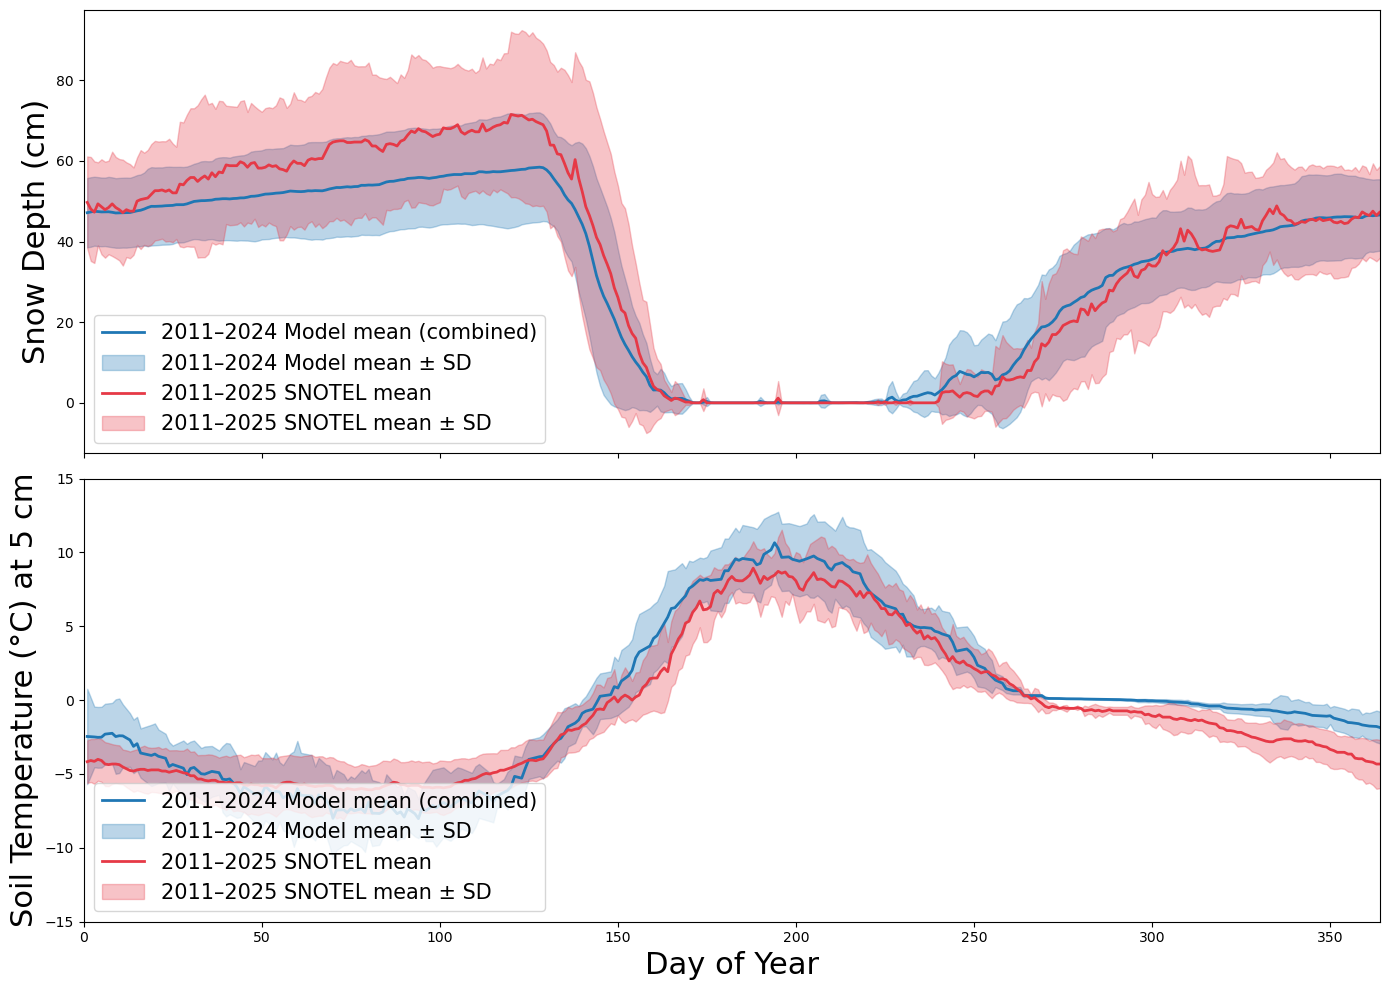

In [20]:
# ── Plot: Snow Depth and Soil Temperature by DOY ────────────────────────────
fig, ax = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Snow depth
ax[0].plot(model_sd_mean_comb.index, model_sd_mean_comb * 100,
           label="2011–2024 Model mean (combined)", color="#1f77b4", linewidth=2)
ax[0].fill_between(model_sd_mean_comb.index,
                   (model_sd_mean_comb - model_sd_std_comb) * 100,
                   (model_sd_mean_comb + model_sd_std_comb) * 100,
                   color="#1f77b4", alpha=0.3, label="2011–2024 Model mean ± SD")
ax[0].plot(obs_sd_mean.index, obs_sd_mean * 100,
           label="2011–2025 SNOTEL mean", color="#e63946", linewidth=2)
ax[0].fill_between(obs_sd_mean.index,
                   (obs_sd_mean - obs_sd_std) * 100,
                   (obs_sd_mean + obs_sd_std) * 100,
                   color="#e63946", alpha=0.3, label="2011–2025 SNOTEL mean ± SD")
ax[0].set_ylabel("Snow Depth (cm)", fontsize=22)
ax[0].legend(loc="lower left", fontsize=15)

# Soil temperature at 5 cm
ax[1].plot(mean_doy_temp_comb.index, mean_temp_comb_smooth,
           label="2011–2024 Model mean (combined)", color="#1f77b4", linewidth=2)
ax[1].fill_between(mean_doy_temp_comb.index,
                   mean_temp_comb_smooth - sd_temp_comb_smooth,
                   mean_temp_comb_smooth + sd_temp_comb_smooth,
                   color="#1f77b4", alpha=0.3, label="2011–2024 Model mean ± SD")
ax[1].plot(obs_st_mean_filtered.index, obs_st_mean_filtered,
           label="2011–2025 SNOTEL mean", color="#e63946", linewidth=2)
ax[1].fill_between(obs_st_mean_filtered.index,
                   obs_st_mean_filtered - obs_st_std.loc[obs_st_mean_filtered.index],
                   obs_st_mean_filtered + obs_st_std.loc[obs_st_mean_filtered.index],
                   color="#e63946", alpha=0.3, label="2011–2025 SNOTEL mean ± SD")
ax[1].set_ylim(-15, 15)
ax[1].set_xlim(0, 364)
ax[1].set_ylabel("Soil Temperature (°C) at 5 cm", fontsize=22)
ax[1].set_xlabel("Day of Year", fontsize=22)
ax[1].legend(loc="lower left", fontsize=15)

plt.tight_layout()
plt.show()

## 6. Model Validation — Water Table & Ice Table Depth

### 6a. Load Field Observations

Field measurements of depth to water (DTW) and depth to ice table (DTI) come from Imnavait Creek IMP sites (IMP09 and IMP19). These are compared against modeled values for 2024.

In [23]:
# ── Load field measurements ───────────────────────────────────────────────────
IMP_obs = pd.read_csv('../data/IMP_dtw_dti.csv')
IMP_obs_date = pd.to_datetime(IMP_obs['Date'])
IMP_dti = IMP_obs['Thaw Depth (cm)']
IMP_dtw = IMP_obs['depth to water (cm)']
IMP_obs['DOY'] = IMP_obs_date.dt.dayofyear

# Continuous DTW sensor data
dtw_csv = pd.read_csv('../data/IMP-DTW-time-series.csv', parse_dates=['Date-Time'])
dtw_csv['DOY'] = dtw_csv['Date-Time'].dt.dayofyear
sensor_cols = dtw_csv.columns.drop(['Date-Time', 'DOY'])
dtw_doy_mean = dtw_csv.groupby('DOY')[sensor_cols].mean().mean(axis=1) * 100  # m → cm
dtw_doy_std  = dtw_csv.groupby('DOY')[sensor_cols].std().mean(axis=1) * 100
obs_doy_min, obs_doy_max = dtw_doy_mean.index.min(), dtw_doy_mean.index.max()

# ── DOY-mean model water and ice table from transect obs ─────────────────────
model_dtw_mean = runobs_transect_1981_2024.groupby('DOY')['water table depth [m]'].mean()
model_dtw_std  = runobs_transect_1981_2024.groupby('DOY')['water table depth [m]'].std()
model_dti_mean = runobs_transect_1981_2024.groupby('DOY')['thaw depth [m]'].mean().rolling(window=12, center=True).mean()
model_dti_std  = runobs_transect_1981_2024.groupby('DOY')['thaw depth [m]'].std().rolling(window=12, center=True).mean()

print("Field and model WTD/DTI data ready.")

Field and model WTD/DTI data ready.


### 6b. Build 2024 Column Model Surface Ponded Depth

Column model surface VisFiles are used to extract ponded depth (water above ground surface), which is added to the water table depth to represent the combined water level.

In [24]:
# ── Load column surface VisFiles ──────────────────────────────────────────────
vis_col_surf_2011_2020 = ats_xdmf.VisFile(rundir, domain='surface', time_unit='d')
vis_col_surf_2011_2020.filterIndices(range(0, len(vis_col_surf_2011_2020.times), 10))

vis_col_surf_2019_2024 = ats_xdmf.VisFile(rundir2, domain='surface', time_unit='d')
vis_col_surf_2019_2024.filterIndices(range(0, len(vis_col_surf_2019_2024.times), 1))

# ── Derive column model epochs ────────────────────────────────────────────────
COL_2011_START = datetime(2011, 1, 1)
COL_2019_START = datetime(2019, 1, 1)
EPOCH_COL_2011 = COL_2011_START - timedelta(days=int(vis_col_surf_2011_2020.times[0]))
EPOCH_COL_2019 = COL_2019_START - timedelta(days=int(vis_col_surf_2019_2024.times[0]))

print(f"Col 2011 sim spans: {EPOCH_COL_2011 + timedelta(days=int(vis_col_surf_2011_2020.times[0]))} → "
      f"{EPOCH_COL_2011 + timedelta(days=int(vis_col_surf_2011_2020.times[-1]))}")
print(f"Col 2019 sim spans: {EPOCH_COL_2019 + timedelta(days=int(vis_col_surf_2019_2024.times[0]))} → "
      f"{EPOCH_COL_2019 + timedelta(days=int(vis_col_surf_2019_2024.times[-1]))}")

Col 2011 sim spans: 2011-01-01 00:00:00 → 2020-07-31 00:00:00
Col 2019 sim spans: 2019-01-01 00:00:00 → 2024-12-19 00:00:00


In [25]:
def compute_ponded_depth_series(vis_surf, epoch):
    """Extract mean ponded depth [m] at each snapshot; return a date-indexed DataFrame."""
    snap_times = np.array(vis_surf.times, dtype=float)
    snap_dates = np.array([epoch + timedelta(days=int(t)) for t in snap_times])
    ponded = np.empty(len(snap_times), dtype=float)
    for n in tqdm(range(len(snap_times)), desc="Ponded depth", leave=False):
        pd_val    = vis_surf.get("surface-ponded_depth", vis_surf.cycles[n])
        ponded[n] = float(np.mean(pd_val))
    return pd.DataFrame({"date": snap_dates, "ponded_m": ponded}).set_index("date").sort_index()

print("Computing ponded depth — 2011–2020...")
df_pond_2011 = compute_ponded_depth_series(vis_col_surf_2011_2020, EPOCH_COL_2011)
print("Computing ponded depth — 2019–2024...")
df_pond_2019 = compute_ponded_depth_series(vis_col_surf_2019_2024, EPOCH_COL_2019)

df_pond_combined = pd.concat([
    df_pond_2011[df_pond_2011.index <= '2019-12-31'],
    df_pond_2019[df_pond_2019.index >= '2020-01-01'],
]).sort_index()
df_pond_combined['DOY']  = pd.to_datetime(df_pond_combined.index).day_of_year
df_pond_combined['year'] = pd.to_datetime(df_pond_combined.index).year

Computing ponded depth — 2011–2020...


Ponded depth:   0%|          | 0/36 [00:00<?, ?it/s]

Computing ponded depth — 2019–2024...


Ponded depth:   0%|          | 0/219 [00:00<?, ?it/s]

### 6c. 2024 Water Table & Ice Table Comparison

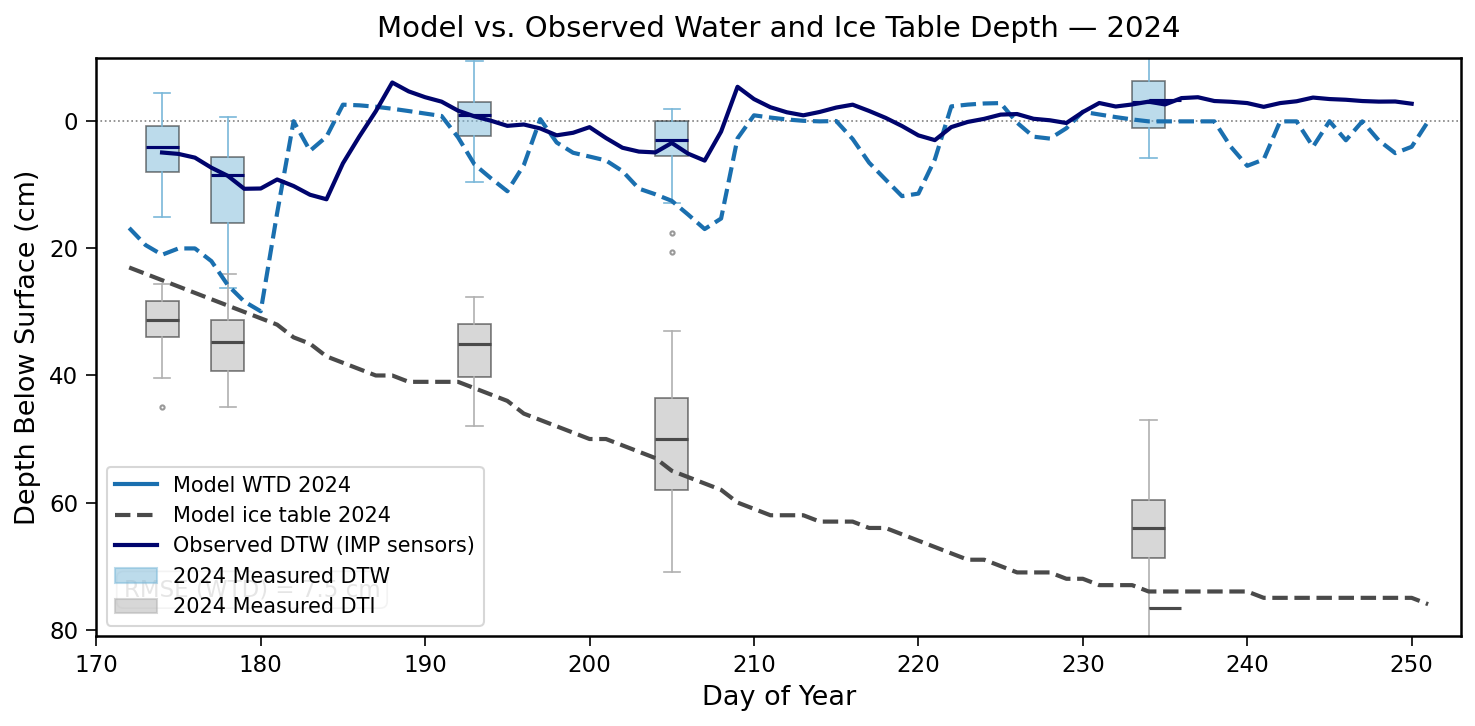

RMSE (WTD): 7.51 cm  (N=77 DOYs)


In [26]:
# ── Rebuild combined column obs with proper calendar dates ────────────────────
_obs1 = pd.read_csv(rundir  + "/observation_columnSpinup.dat", comment='#')
_obs1['Date'] = pd.date_range(start='2011-01-01', periods=len(_obs1), freq='D')
_obs1['DOY']  = _obs1['Date'].dt.dayofyear
_obs2 = pd.read_csv(rundir2 + "/observation_columnSpinup.dat", comment='#')
_obs2['Date'] = pd.date_range(start='2019-01-01', periods=len(_obs2), freq='D')
_obs2['DOY']  = _obs2['Date'].dt.dayofyear
_obs1_trim = _obs1[_obs1['Date'] <= '2019-12-31'].copy()
_obs2_trim = _obs2[_obs2['Date'] >= '2020-01-01'].copy()
_runobs_combined = pd.concat([_obs1_trim, _obs2_trim], ignore_index=True)
_runobs_combined['year'] = _runobs_combined['Date'].dt.year

# ── 2024 water table from column obs ─────────────────────────────────────────
_obs_2024 = _runobs_combined[_runobs_combined['year'] == 2024]
model_dtw_2024_mean = _obs_2024.groupby('DOY')['water table depth [m]'].mean() * 100
model_dti_2024_mean = _obs_2024.groupby('DOY')['thaw depth [m]'].mean() * 100

# ── Interpolate 2024 ponded depth to daily DOY resolution ────────────────────
pond_2024_raw = (df_pond_combined[df_pond_combined['year'] == 2024]
                 .groupby('DOY')['ponded_m'].mean() * 10000)   # m → cm
doy_daily = np.arange(obs_doy_min, obs_doy_max + 1)
cs = CubicSpline(pond_2024_raw.index.values, pond_2024_raw.values)
pond_2024 = pd.Series(cs(doy_daily).clip(min=0), index=doy_daily)

# ── Combine WTD + ponding ─────────────────────────────────────────────────────
all_doy = model_dtw_2024_mean.index.union(pond_2024.index)
wtd_aligned  = model_dtw_2024_mean.reindex(all_doy, fill_value=np.nan)
pond_aligned = pond_2024.reindex(all_doy, fill_value=0.0)
model_dtw_2024_combined = wtd_aligned - pond_aligned

model_clipped     = model_dtw_2024_combined.loc[obs_doy_min:obs_doy_max]
model_dti_clipped = model_dti_2024_mean.loc[obs_doy_min:obs_doy_max]

# ── RMSE on common DOYs ───────────────────────────────────────────────────────
common_doy = model_clipped.index.intersection(dtw_doy_mean.index)
m = model_clipped.loc[common_doy].values
o = dtw_doy_mean.loc[common_doy].values
mask = ~np.isnan(m) & ~np.isnan(o)
rmse = np.sqrt(np.mean((m[mask] - o[mask]) ** 2))

# ── Plot ──────────────────────────────────────────────────────────────────────
C_WTD_MODEL = '#1a6faf'; C_WTD_OBS = "#00046d"; C_WTD_BOX = '#7ab8d9'; C_WTD_MED = '#00046d'
C_DTI_MODEL = '#4a4a4a'; C_DTI_BOX = '#b0b0b0'; C_DTI_MED = '#4a4a4a'

plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 12,
                     'axes.linewidth': 1.2, 'xtick.direction': 'out', 'ytick.direction': 'out',
                     'xtick.major.size': 5, 'ytick.major.size': 5})

fig, ax = plt.subplots(figsize=(10, 5), dpi=150)

# Field boxplots
ax.boxplot([IMP_dtw[IMP_obs['DOY'] == doy] for doy in sorted(IMP_obs['DOY'].unique())],
           positions=sorted(IMP_obs['DOY'].unique()), patch_artist=True,
           boxprops=dict(facecolor=C_WTD_BOX, alpha=0.5, linewidth=0.8),
           medianprops=dict(color=C_WTD_MED, linewidth=1.5),
           whiskerprops=dict(linewidth=0.8, color=C_WTD_BOX),
           capprops=dict(linewidth=0.8, color=C_WTD_BOX),
           flierprops=dict(marker='o', markersize=2, color=C_WTD_BOX, alpha=0.4),
           widths=2, manage_ticks=False)
ax.boxplot([IMP_dti[IMP_obs['DOY'] == doy] for doy in sorted(IMP_obs['DOY'].unique())],
           positions=sorted(IMP_obs['DOY'].unique()), patch_artist=True,
           boxprops=dict(facecolor=C_DTI_BOX, alpha=0.5, linewidth=0.8),
           medianprops=dict(color=C_DTI_MED, linewidth=1.5),
           whiskerprops=dict(linewidth=0.8, color=C_DTI_BOX),
           capprops=dict(linewidth=0.8, color=C_DTI_BOX),
           flierprops=dict(marker='o', markersize=2, color=C_DTI_BOX, alpha=0.4),
           widths=2, manage_ticks=False)

# Model lines
ax.plot(model_clipped.index, model_clipped.values,
        color=C_WTD_MODEL, linewidth=2, linestyle='--', zorder=4,
        label='Model water table depth 2024 (incl. ponding)')
ax.plot(dtw_doy_mean.index, dtw_doy_mean.values,
        color=C_WTD_OBS, linewidth=2, linestyle='-', zorder=4,
        label='Observed DTW (IMP sensors, 2024)')
ax.plot(model_dti_clipped.index, model_dti_clipped.values,
        color=C_DTI_MODEL, linewidth=2, linestyle='--', zorder=4,
        label='Model ice table depth 2024')

ax.axhline(0, color='gray', linewidth=0.8, linestyle='dotted', zorder=1)
ax.text(0.02, 0.06, f'RMSE (WTD) = {rmse:.1f} cm', transform=ax.transAxes, fontsize=11,
        verticalalignment='bottom',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='gray', linewidth=0.8, alpha=0.9))
ax.set_xlabel('Day of Year', fontsize=13)
ax.set_ylabel('Depth Below Surface (cm)', fontsize=13)
ax.set_title('Model vs. Observed Water and Ice Table Depth — 2024', fontsize=14, pad=10)
ax.set_xlim(obs_doy_min - 2, obs_doy_max + 2)
ax.set_ylim(-10, max(model_clipped.max(), model_dti_clipped.max()) + 5)
ax.invert_yaxis()
ax.tick_params(axis='both', labelsize=11)
ax.legend(handles=[
    plt.Line2D([0],[0], color=C_WTD_MODEL, linewidth=2, linestyle='-', label='Model WTD 2024'),
    plt.Line2D([0],[0], color=C_DTI_MODEL, linewidth=2, linestyle='--', label='Model ice table 2024'),
    plt.Line2D([0],[0], color=C_WTD_OBS,   linewidth=2, label='Observed DTW (IMP sensors)'),
    Patch(facecolor=C_WTD_BOX, alpha=0.5, edgecolor=C_WTD_BOX, label='2024 Measured DTW'),
    Patch(facecolor=C_DTI_BOX, alpha=0.5, edgecolor=C_DTI_BOX, label='2024 Measured DTI'),
], fontsize=10, frameon=True, framealpha=0.9, edgecolor='lightgray')
plt.tight_layout()
plt.show()
print(f"RMSE (WTD): {rmse:.2f} cm  (N={mask.sum()} DOYs)")

## 7. Zero-Curtain Duration Analysis

The **zero curtain (ZC)** is the phase-transition period during freeze-back when soil temperature remains near 0 °C as latent heat is released. Zero-curtain duration is defined as the number of days a cell's temperature falls within ±0.2 K of 273.15 K during the freeze-back season (Sep 1 → Jun 30 of the following year).

### 7a. Zero-Curtain Map Function

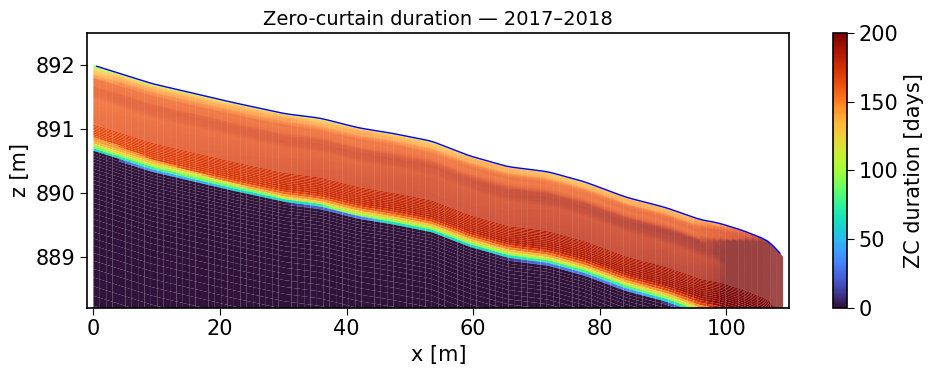

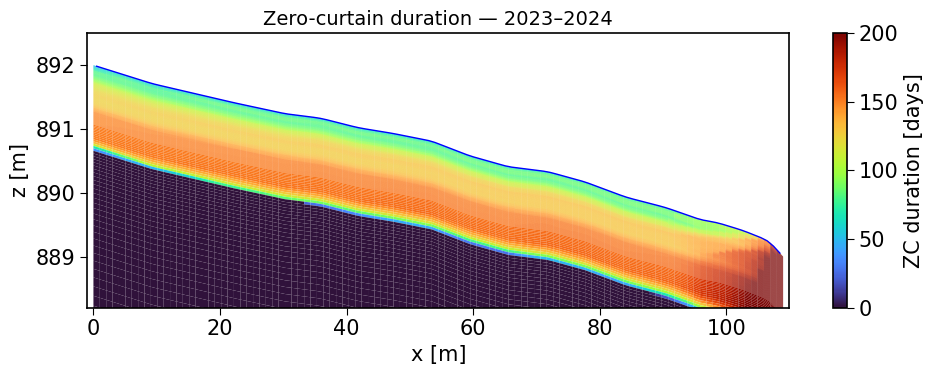

In [27]:
T_FREEZE = 273.15   # K
T_TOL    = 0.2      # K  — zero-curtain tolerance band

fig, counts = plot_zc_duration(
    vis=vis_1981_2020,
    vis_surf=vis_surf_1981_2020,
    epoch=EPOCH_1981,
    target_year=2017,
    elev=elev,
)

fig, counts2 = plot_zc_duration(
    vis=vis_2019_2024,
    vis_surf=vis_surf_2019_2024,
    epoch=EPOCH_2019,
    target_year=2023,
    elev=elev,
)

### 7b. January 22 Temperature Cross-Section (Example: 2024)

A single winter snapshot (January 22, 2024) is shown to illustrate the spatial distribution of subsurface temperature across the transect. The custom colormap highlights frozen (blue→red gradient below 0 °C), the freezing isotherm (black), and thawed/unfrozen cells (grey).

> To reproduce maps for all years (1981–2025), change `example_year` to any value or wrap the cell in a `for year in range(1981, 2025)` loop.


Plotting [2019–2024] cycle index 1847, actual date 2024-01-22


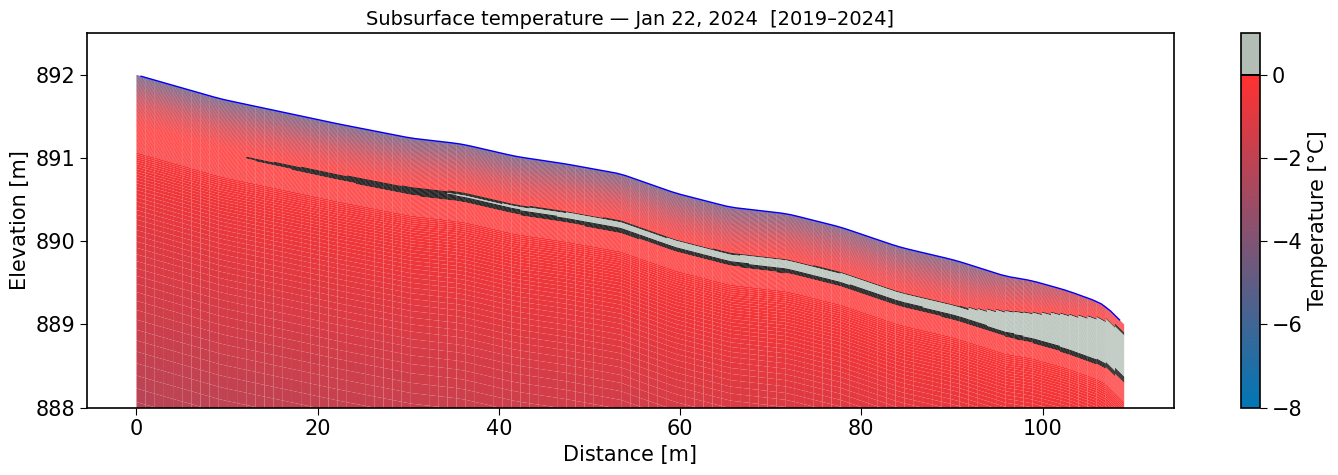

In [28]:
# ── Build a custom colormap: blue→red below 0°C | black at 0°C | grey above ─
vmin_jan, vmax_jan = -8, 1
N = 256
temps_arr = np.linspace(vmin_jan, vmax_jan, N)
cmap_colors = np.zeros((N, 4))

blue  = np.array(mcolors.to_rgba('#0077B6'))
red   = np.array(mcolors.to_rgba('#FF3131'))
grey  = np.array(mcolors.to_rgba('#B2BEB5'))
black = np.array([0, 0, 0, 1])

zero_idx = np.argmin(np.abs(temps_arr - 0))
for i in range(zero_idx):
    frac = i / max(zero_idx - 1, 1)
    cmap_colors[i] = blue * (1 - frac) + red * frac
cmap_colors[zero_idx] = black
cmap_colors[zero_idx + 1:] = grey

cmap_custom = mcolors.ListedColormap(cmap_colors)

# ── Plot Jan 22 for a single example year ────────────────────────────────────
example_year = 2024   # ← change this to any year between 1981 and 2024

target_date = datetime(example_year, 1, 22)

if target_date < CUTOFF_DATE:
    vis_jan      = vis_1981_2020
    vis_surf_jan = vis_surf_1981_2020
    epoch_jan    = EPOCH_1981
    sim_label    = "1981–2020"
else:
    vis_jan      = vis_2019_2024
    vis_surf_jan = vis_surf_2019_2024
    epoch_jan    = EPOCH_2019
    sim_label    = "2019–2024"

day_index = (target_date - epoch_jan).days
idx = int(np.argmin(np.abs(vis_jan.times - day_index)))
actual_date = epoch_jan + timedelta(days=int(vis_jan.times[idx]))
print(f"Plotting [{sim_label}] cycle index {idx}, actual date {actual_date.date()}")

temp_jan = vis_jan.get("temperature", vis_jan.cycles[idx]) - 273.15

plt.rcParams['font.size'] = 15
fig, ax = plt.subplots(figsize=(15, 5))
poly_temp = vis_jan.getMeshPolygons(cmap=cmap_custom, linewidth=0)
poly_temp.set_array(temp_jan)
poly_temp.set_clim(vmin_jan, vmax_jan)
ax.add_collection(poly_temp)
plt.colorbar(poly_temp, ax=ax).set_label("Temperature [°C]")
ax.plot(vis_surf_jan.centroids[:, 0], elev, 'b', linewidth=1, label='Surface elevation')
ax.set_title(f"Subsurface temperature — Jan 22, {example_year}  [{sim_label}]", fontsize=14)
ax.set_ylim(888, 892.5)
ax.set_xlabel("Distance [m]")
ax.set_ylabel("Elevation [m]")
ax.autoscale_view()
plt.tight_layout()
plt.show()

### 7c. Compute ZC Statistics for All Winters (1981–2023)

For each winter, we compute:
1. **Area-weighted mean ZC duration** — how long (days) the average cell spends in the zero curtain
2. **ZC area as % of the time-averaged active layer area**

In [29]:
records = []

for winter_year in tqdm(range(1981, 2024), desc="Processing winters"):
    thaw_season_start = datetime(winter_year,     5,  1)
    thaw_season_end   = datetime(winter_year,    10, 31)
    freeze_search_cap = datetime(winter_year + 1, 6, 30)

    if datetime(winter_year, 9, 1) < CUTOFF_DATE:
        vis = vis_1981_2020; epoch = EPOCH_1981
        obs = runobs_transect_1981_2020; cell_areas = cell_areas_sim1; sim_label = "1981–2020"
    else:
        vis = vis_2019_2024; epoch = EPOCH_2019
        obs = runobs_transect_2019_2024; cell_areas = cell_areas_sim2; sim_label = "2019–2024"

    ncells     = len(cell_areas)
    snap_times = np.array(vis.times, dtype=float)
    obs_times  = obs['time [d]'].to_numpy()
    obs_dti    = obs['thaw depth [m]'].to_numpy()

    thaw_start_day = (thaw_season_start - epoch).days
    thaw_end_day   = (thaw_season_end   - epoch).days
    freeze_cap_day = (freeze_search_cap - epoch).days

    thaw_snap_start = max(0, int(np.searchsorted(snap_times, thaw_start_day, side='left')))
    thaw_snap_end   = max(0, min(int(np.searchsorted(snap_times, thaw_end_day, side='left')), len(snap_times)-1))
    t_window_lo = snap_times[thaw_snap_start]
    t_window_hi = snap_times[thaw_snap_end]

    obs_in_thaw = (obs_times >= t_window_lo) & (obs_times <= t_window_hi)
    if not np.any(obs_in_thaw):
        continue
    peak_thaw_obs_time = np.asarray(obs_times[obs_in_thaw])[int(np.argmax(obs_dti[obs_in_thaw]))]
    freeze_start_snap  = min(int(np.searchsorted(snap_times, peak_thaw_obs_time, side='right')), len(snap_times)-2)

    freeze_cap_snap = max(0, min(int(np.searchsorted(snap_times, freeze_cap_day, side='left')), len(snap_times)-1))
    if freeze_cap_snap <= freeze_start_snap + 1:
        continue

    thawed_area_series = np.asarray([
        float(cell_areas[vis.get("temperature", vis.cycles[i]) > (T_FREEZE - T_TOL)].sum())
        for i in range(freeze_start_snap, freeze_cap_snap + 1)
    ], dtype=float)
    if thawed_area_series.size < 2:
        continue

    freeze_end_snap = min(
        freeze_start_snap + int(np.argmin(thawed_area_series[1:])) + 1, len(snap_times)-1)
    if freeze_end_snap <= freeze_start_snap + 1:
        continue

    cell_zc_duration   = np.zeros(ncells, dtype=float)
    cell_thaw_duration = np.zeros(ncells, dtype=float)
    for i in range(freeze_start_snap, freeze_end_snap):
        T  = vis.get("temperature", vis.cycles[i])
        dt = snap_times[i + 1] - snap_times[i]
        if dt <= 0: continue
        cell_zc_duration[np.abs(T - T_FREEZE) <= T_TOL] += dt
        cell_thaw_duration[T > (T_FREEZE - T_TOL)]       += dt

    window_length_days = float(snap_times[freeze_end_snap] - snap_times[freeze_start_snap])
    if window_length_days <= 0: continue

    zc_cells = cell_zc_duration > 0
    mean_zc_duration_days = (float(np.dot(cell_areas[zc_cells], cell_zc_duration[zc_cells]) / cell_areas[zc_cells].sum())
                             if np.any(zc_cells) else np.nan)
    avg_AL_area = float(np.dot(cell_areas, cell_thaw_duration)) / window_length_days
    avg_ZC_area = float(np.dot(cell_areas, cell_zc_duration))   / window_length_days
    zc_area_pct = 100.0 * avg_ZC_area / avg_AL_area if avg_AL_area > 0 else np.nan

    records.append({
        "winter"                : f"{winter_year}–{str((winter_year+1)%100).zfill(2)}",
        "year"                  : winter_year,
        "sim"                   : sim_label,
        "mean_zc_duration_days" : mean_zc_duration_days,
        "zc_area_pct_of_AL"     : zc_area_pct,
        "window_length_days"    : window_length_days,
        "avg_AL_area_m2"        : avg_AL_area,
        "avg_ZC_area_m2"        : avg_ZC_area,
        "freeze_back_start"     : (epoch + timedelta(days=int(snap_times[freeze_start_snap]))).date(),
        "freeze_back_end"       : (epoch + timedelta(days=int(snap_times[freeze_end_snap]))).date(),
    })

df_zc = pd.DataFrame(records).sort_values("year").reset_index(drop=True).set_index("winter")
print(df_zc.head())

Processing winters:   0%|          | 0/43 [00:00<?, ?it/s]

         year        sim  mean_zc_duration_days  zc_area_pct_of_AL  \
winter                                                               
1981–82  1981  1981–2020              91.351661          92.174930   
1982–83  1982  1981–2020              85.132498          94.530684   
1983–84  1983  1981–2020              94.954636          93.612066   
1984–85  1984  1981–2020              74.136948          94.002733   
1985–86  1985  1981–2020              73.377015          92.596604   

         window_length_days  avg_AL_area_m2  avg_ZC_area_m2 freeze_back_start  \
winter                                                                          
1981–82               196.0       39.167756       36.102851        1981-08-14   
1982–83               165.0       45.732412       43.231162        1982-08-29   
1983–84               174.0       47.468305       44.436061        1983-08-19   
1984–85               132.0       45.044693       42.343243        1984-08-20   
1985–86               1

### 7d. Zero-Curtain Duration Trend (1981–2023)

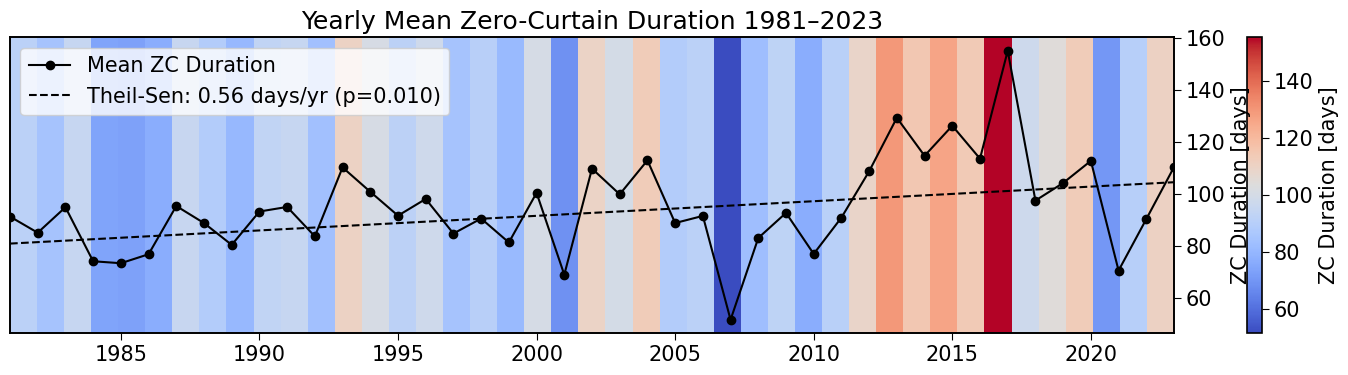

In [30]:
zc_years = df_zc['year'].values
zc_dur   = df_zc['mean_zc_duration_days'].values

ts     = theilslopes(zc_dur, zc_years)
mk_res = mk.original_test(zc_dur)
trend  = ts.slope * zc_years + ts.intercept

fig, ax1 = plt.subplots(figsize=(15, 4))
ax1.imshow(zc_dur.reshape(1, -1), aspect='auto', cmap='coolwarm',
           extent=[zc_years[0], zc_years[-1], 0, 1],
           vmin=np.nanmin(zc_dur), vmax=np.nanmax(zc_dur))
ax1.set_yticks([]); ax1.set_xlim(zc_years[0], zc_years[-1])
ax1.set_title('Yearly Mean Zero-Curtain Duration 1981–2023')
plt.colorbar(ax1.images[0], ax=ax1, orientation='vertical').set_label('ZC Duration [days]')
ax2 = ax1.twinx()
ax2.plot(zc_years, zc_dur, marker='o', linestyle='-', color='black', label='Mean ZC Duration')
ax2.plot(zc_years, trend, linestyle='--', color='k',
         label=f'Theil-Sen: {ts.slope:.2f} days/yr (p={mk_res.p:.3f})')
ax2.set_ylabel('ZC Duration [days]'); ax2.legend(loc='upper left'); ax2.grid(False)
plt.tight_layout(); plt.show()

### 7e. ZC Duration vs Winter Temperature and Snowfall

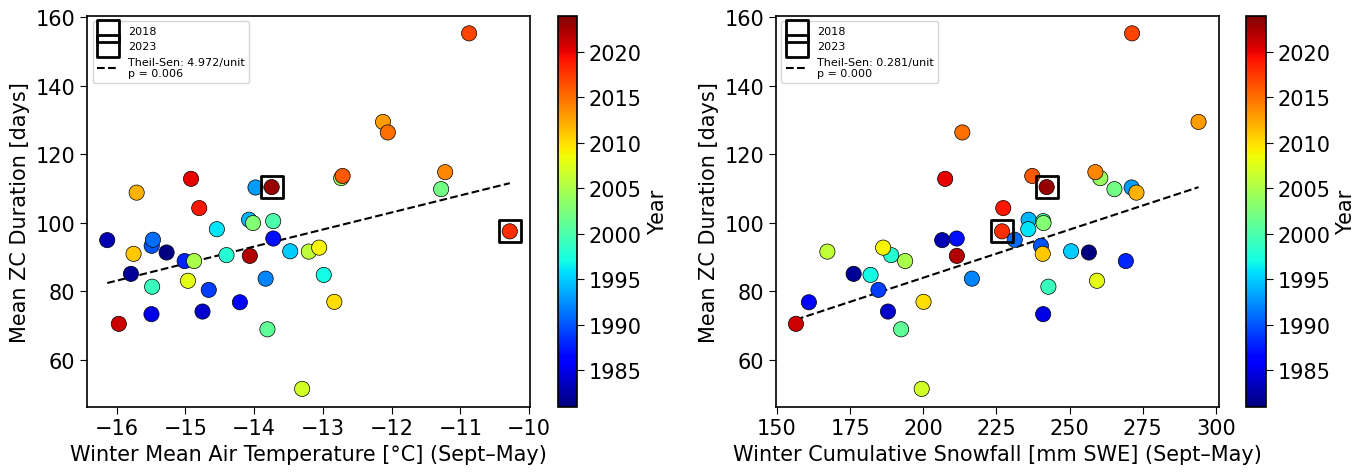

In [31]:
def compute_winter_temp(df_met, years):
    """Mean air temperature for Sep 1 of year Y through May 31 of year Y+1."""
    return pd.DataFrame([{'year': yr,
        'winter_temp': df_met.loc[
            (df_met.index >= pd.Timestamp(f'{yr}-09-01')) &
            (df_met.index <= pd.Timestamp(f'{yr+1}-05-31')), 'air temperature [C]'].mean()}
        for yr in years])

def compute_winter_snow(df_met, years):
    """Cumulative snowfall (mm SWE) for Sep 1 → May 31."""
    return pd.DataFrame([{'year': yr,
        'snowfall': (df_met.loc[
            (df_met.index >= pd.Timestamp(f'{yr}-09-01')) &
            (df_met.index <= pd.Timestamp(f'{yr+1}-05-31')),
            'Precipitation Snow [m SWE s^-1]'] * 86400 * 1000).sum()}
        for yr in years])

winter_temp_df = compute_winter_temp(df_combined, zc_years)
winter_snow_df = compute_winter_snow(df_combined, zc_years)
merged = df_zc[['year', 'mean_zc_duration_days']].merge(winter_temp_df, on='year').merge(winter_snow_df, on='year')

years_m = merged['year'].values
zc_m    = merged['mean_zc_duration_days'].values
snow    = merged['snowfall'].values
temp    = merged['winter_temp'].values
highlight_years = [2018, 2023]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for ax, x, xlabel in [
    (ax1, temp, 'Winter Mean Air Temperature [°C] (Sept–May)'),
    (ax2, snow, 'Winter Cumulative Snowfall [mm SWE] (Sept–May)'),
]:
    sc = ax.scatter(x, zc_m, c=years_m, cmap='jet', vmin=1981, vmax=2024,
                    s=120, edgecolors='black', linewidths=0.5, zorder=3)
    for hy in highlight_years:
        msk = years_m == hy
        ax.scatter(x[msk], zc_m[msk], marker='s', s=250,
                   facecolors='none', edgecolors='black', linewidths=2, zorder=5, label=str(hy))
    ts_sc = theilslopes(zc_m, x)
    tau, p_val = kendalltau(zc_m, x)
    x_line = np.linspace(x.min(), x.max(), 200)
    ax.plot(x_line, ts_sc.slope * x_line + ts_sc.intercept, '--', color='k', linewidth=1.5,
            label=f'Theil-Sen: {ts_sc.slope:.3f}/unit\np = {p_val:.3f}')
    ax.set_xlabel(xlabel); ax.set_ylabel('Mean ZC Duration [days]')
    ax.legend(fontsize=8); plt.colorbar(sc, ax=ax, label='Year')
plt.tight_layout(); plt.show()

## 8. Active Layer (Unfrozen Area) Time Series

The total unfrozen (thawed) cross-sectional area [m²] is computed for each snapshot by summing cell areas where temperature exceeds T_FREEZE − T_TOL. Annual maximum values and a Theil–Sen trend are shown.

In [32]:
def compute_unfrozen_area_series(vis_obj, cell_areas, epoch, date_start, date_end):
    """Return date-indexed DataFrame of unfrozen area [m²] for all snapshots in [date_start, date_end]."""
    snap_times = np.array(vis_obj.times, dtype=float)
    snap_dates = np.array([epoch + timedelta(days=int(t)) for t in snap_times])
    mask = (snap_dates >= date_start) & (snap_dates <= date_end)
    idxs = np.nonzero(mask)[0]
    if len(idxs) == 0:
        raise RuntimeError(f"No snapshots between {date_start} and {date_end}.")
    unfrozen = np.empty(len(idxs), dtype=float)
    for k, j in enumerate(tqdm(idxs, desc=f"  {date_start.year}–{date_end.year}", leave=False)):
        T = vis_obj.get("temperature", vis_obj.cycles[j])
        unfrozen[k] = float(cell_areas[T > (T_FREEZE - T_TOL)].sum())
    return pd.DataFrame({"date": snap_dates[idxs], "snap_time_d": snap_times[idxs],
                          "unfrozen_area_m2": unfrozen}).set_index("date").sort_index()

print("Processing sim1 (1981–2019)...")
df_ua_sim1 = compute_unfrozen_area_series(vis_1981_2020, cell_areas_sim1, EPOCH_1981,
                                           datetime(1981,1,1), datetime(2019,12,31))
print("Processing sim2 (2020–2024)...")
df_ua_sim2 = compute_unfrozen_area_series(vis_2019_2024, cell_areas_sim2, EPOCH_2019,
                                           datetime(2020,1,1), datetime(2024,12,31))
df_unfrozen = pd.concat([df_ua_sim1, df_ua_sim2]).sort_index()
print(f"Combined: {df_unfrozen.index[0].date()} → {df_unfrozen.index[-1].date()} ({len(df_unfrozen)} snapshots)")

Processing sim1 (1981–2019)...


  1981–2019:   0%|          | 0/14244 [00:00<?, ?it/s]

Processing sim2 (2020–2024)...


  2020–2024:   0%|          | 0/1825 [00:00<?, ?it/s]

Combined: 1981-01-01 → 2024-12-30 (16069 snapshots)


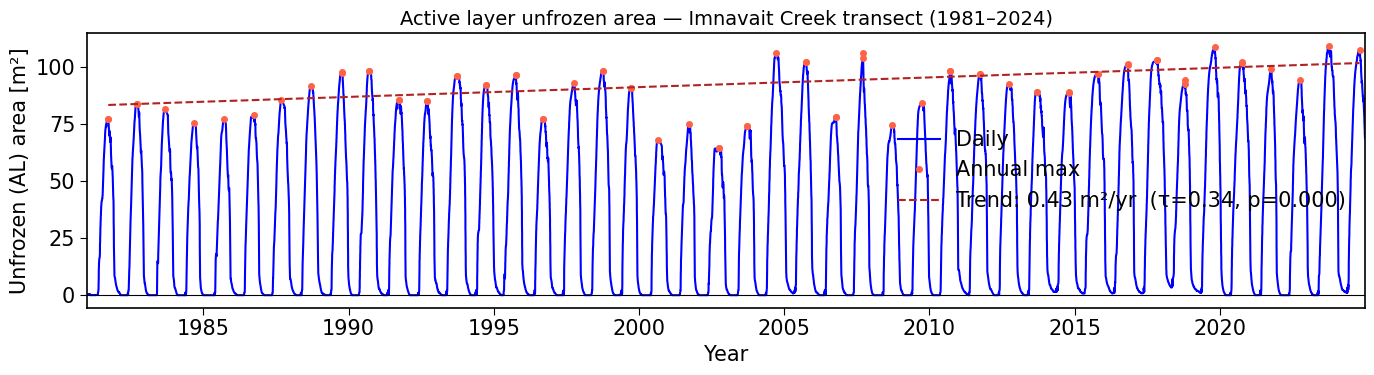

In [33]:
annual_max_idx = df_unfrozen["unfrozen_area_m2"].resample('YE').apply(lambda s: s.idxmax())
annual_max = df_unfrozen.loc[annual_max_idx, "unfrozen_area_m2"]
ua_years = np.array([d.year for d in annual_max.index])
ua_values = annual_max.values
slope_ua, intercept_ua, _, _ = theilslopes(ua_values, ua_years)
tau_ua, p_ua = kendalltau(ua_years, ua_values)
trendline_ua = intercept_ua + slope_ua * ua_years

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df_unfrozen.index, df_unfrozen["unfrozen_area_m2"], color='blue', linewidth=1.5, label='Daily')
ax.plot(annual_max.index, annual_max.values, 'o', color='tomato', markersize=4, label='Annual max')
ax.plot(annual_max.index, trendline_ua, '--', color='firebrick', linewidth=1.5,
        label=f'Trend: {slope_ua:.2f} m²/yr  (τ={tau_ua:.2f}, p={p_ua:.3f})')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel("Unfrozen (AL) area [m²]"); ax.set_xlabel("Year")
ax.set_title("Active layer unfrozen area — Imnavait Creek transect (1981–2024)", fontsize=14)
ax.set_xlim(df_unfrozen.index[0], df_unfrozen.index[-1])
ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 9. Maximum Thaw Depth Analysis

Ice-table depth is extracted from the ATS mesh by identifying the first cell column (at x ≈ 90 m, the hillslope midpoint) with ice saturation exceeding a threshold. Annual maximum thaw depths are computed and a Theil–Sen trend is fitted.

> **Note:** If `thaw_depth_vis_1981_2024.csv` already exists from a previous run, the cell extraction loop (which is slow) can be skipped by loading from CSV.

In [34]:
def build_ice_table_df(vis, x_min=90, dx=1.0092592592592524, thresh=0.9):
    """Extract ice-table depth time series for the column at horizontal position x_min."""
    x_max = x_min + 2 * dx
    depths, times_list = [], []
    poly  = vis.getMeshPolygons(cmap='jet_r', linewidth=0)
    paths = poly.get_paths()
    for n in range(len(vis.times)):
        cycle = vis.cycles[n]
        t     = vis.times[n]
        selected_paths = filter_paths(paths, x_min, x_max)
        sat_ice = vis.get("saturation_ice", cycle)
        sat_ice_subset = extract_data_for_paths(sat_ice, paths, x_min, x_max)
        closepoly_y = np.array([p.vertices[-1, 1] for p in selected_paths])
        depths.append(determine_ice_table_depth(sat_ice_subset, closepoly_y))
        times_list.append(t)
    return pd.DataFrame({"time": times_list, "ice_table_depth": depths})

In [35]:
import os

CSV_THAW = "thaw_depth_vis_1981_2024.csv"

if os.path.exists(CSV_THAW):
    # Fast path: load from pre-computed CSV
    df_ice = pd.read_csv(CSV_THAW)
    print(f"Loaded {CSV_THAW} ({len(df_ice)} rows)")
else:
    # Slow path: extract from VisFiles
    print("Processing 1981–2020 sim (slow — may take several minutes)...")
    df_ice_s1 = build_ice_table_df(vis_1981_2020)
    df_ice_s1['date'] = [EPOCH_1981 + timedelta(days=float(t)) for t in df_ice_s1['time']]

    print("Processing 2019–2024 sim...")
    df_ice_s2 = build_ice_table_df(vis_2019_2024)
    df_ice_s2['date'] = [EPOCH_2019 + timedelta(days=float(t)) for t in df_ice_s2['time']]

    df_ice_s1 = df_ice_s1[df_ice_s1['date'] < CUTOFF_DATE]
    df_ice_s2 = df_ice_s2[df_ice_s2['date'] >= CUTOFF_DATE]
    df_ice = (pd.concat([df_ice_s1, df_ice_s2])
              .drop_duplicates('date').sort_values('date').reset_index(drop=True))
    df_ice.to_csv(CSV_THAW, index=False)
    print(f"Saved {CSV_THAW}")

df_ice['date'] = pd.to_datetime(df_ice['date'])
df_ice['year'] = df_ice['date'].dt.year
df_ice['doy']  = df_ice['date'].dt.dayofyear
years_ice = sorted(df_ice['year'].unique())

Processing 1981–2020 sim (slow — may take several minutes)...
Processing 2019–2024 sim...
Saved thaw_depth_vis_1981_2024.csv


### 9a. Thaw Depth Seasonal Curves by Year

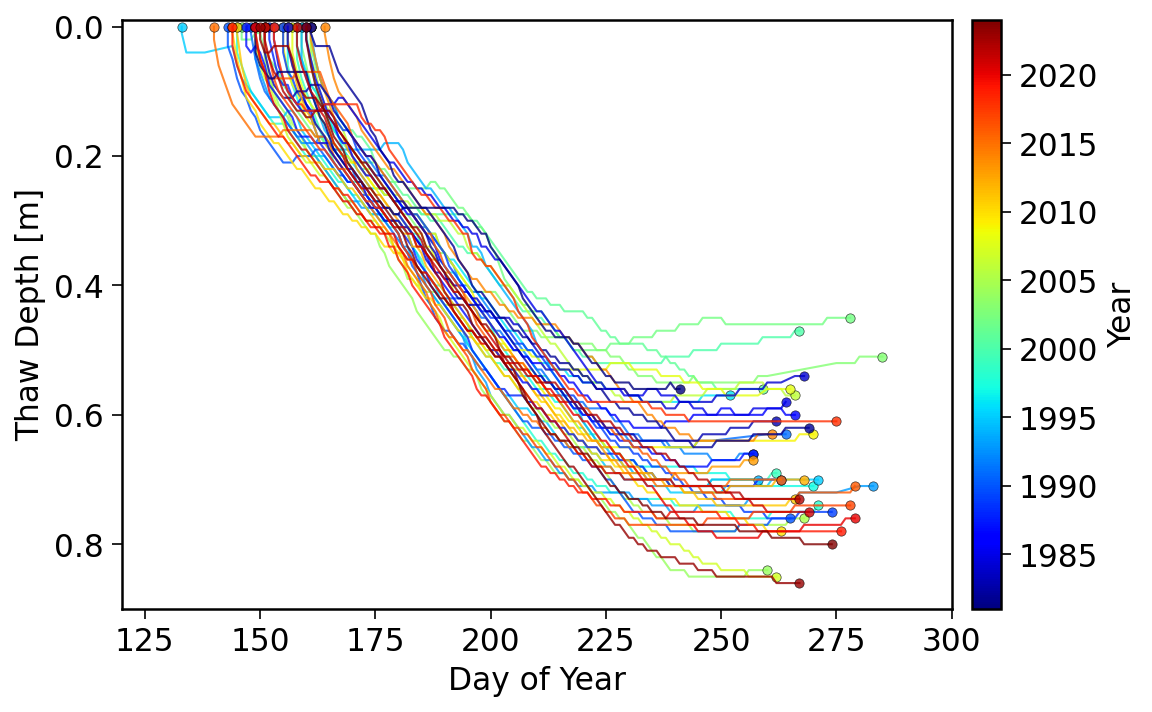

In [36]:
year_min, year_max = min(years_ice), max(years_ice)
year_mid = 2000
fig, ax = plt.subplots(figsize=(8, 5), dpi=150)
cmap_ice = plt.get_cmap('jet')
norm_ice = mcolors.Normalize(vmin=year_min, vmax=year_max)

for y in sorted(years_ice):
    w = df_ice[(df_ice['year'] == y) & (df_ice['ice_table_depth'] > 0)].sort_values('doy')
    if w.empty: continue
    color = cmap_ice(norm_ice(y))
    zorder = abs(y - year_mid)
    first_doy  = w['doy'].iloc[0]
    doy_plot   = np.concatenate([[first_doy], w['doy'].values])
    depth_plot = np.concatenate([[0.0], w['ice_table_depth'].values])
    ax.plot(doy_plot, depth_plot, lw=1.0, color=color, alpha=0.8, zorder=zorder)
    ax.scatter([doy_plot[0], doy_plot[-1]], [depth_plot[0], depth_plot[-1]],
               color=color, alpha=0.8, s=20, edgecolor='k', linewidth=0.3, zorder=zorder+0.1)

ax.invert_yaxis()
ax.set_xlim(120, 300); ax.set_ylim(0.90, -0.01)
ax.set_xlabel('Day of Year'); ax.set_ylabel('Thaw Depth [m]')
sm = ScalarMappable(norm=norm_ice, cmap=cmap_ice)
sm.set_array([])
fig.colorbar(sm, ax=ax, pad=0.02).set_label('Year')
plt.tight_layout(); plt.show()

### 9b. Annual Maximum Thaw Depth Trend

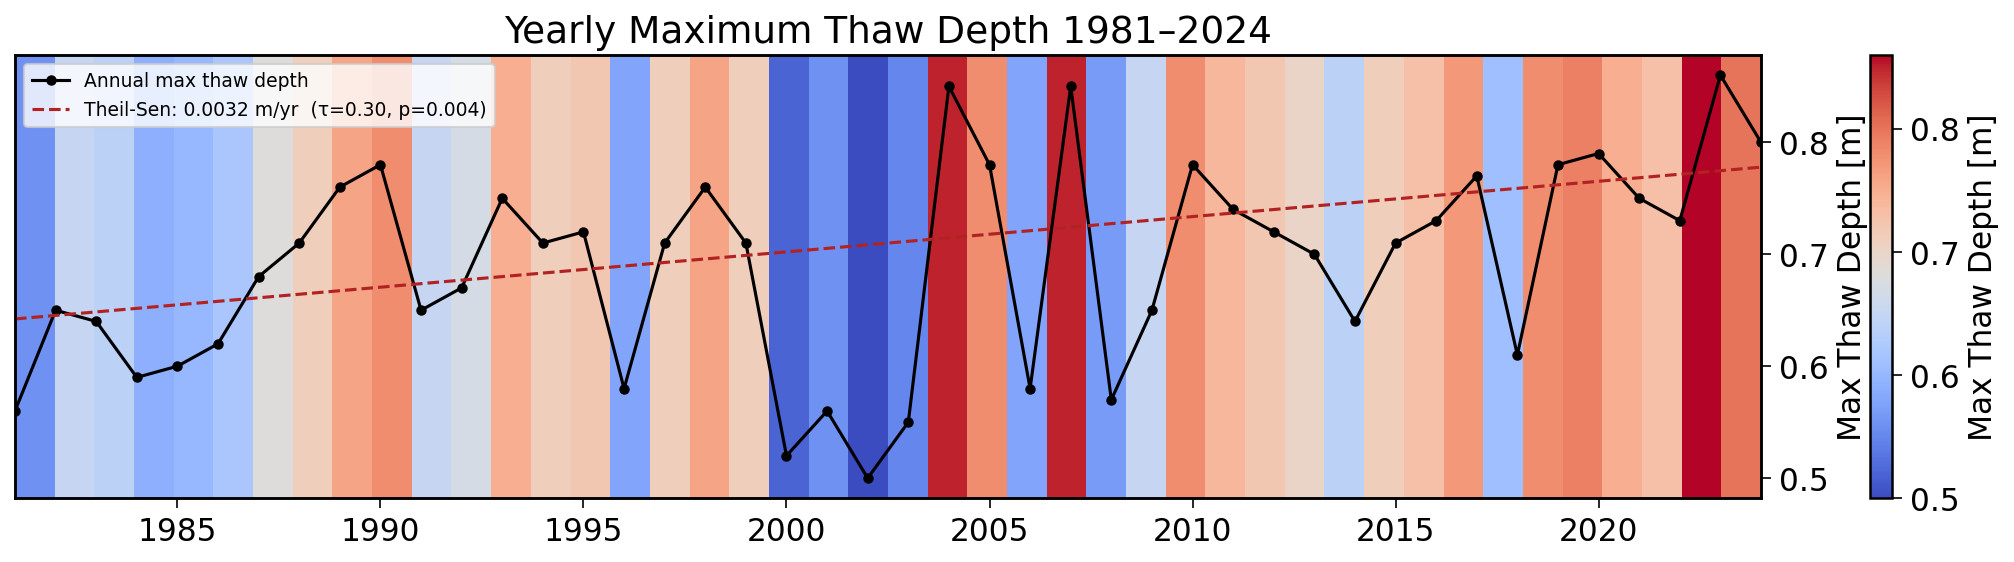

In [37]:
max_thaw = (df_ice[df_ice['ice_table_depth'] > 0]
            .groupby('year')['ice_table_depth'].max()
            .reset_index()
            .rename(columns={'ice_table_depth': 'max_thaw_depth'}))
years_ts  = max_thaw['year'].values
depths_ts = max_thaw['max_thaw_depth'].values

ts_th = theilslopes(depths_ts, years_ts)
tau_th, p_th = kendalltau(years_ts, depths_ts)
trend_th = ts_th.slope * years_ts + ts_th.intercept

fig, ax1 = plt.subplots(figsize=(15, 4), dpi=150)
ax1.imshow(depths_ts.reshape(1, -1), aspect='auto', cmap='coolwarm',
           extent=[years_ts[0], years_ts[-1], 0, 1],
           vmin=depths_ts.min(), vmax=depths_ts.max())
ax1.set_yticks([]); ax1.set_xlim(years_ts[0], years_ts[-1])
ax1.set_title('Yearly Maximum Thaw Depth 1981–2024')
plt.colorbar(ax1.images[0], ax=ax1, orientation='vertical').set_label('Max Thaw Depth [m]')
ax2 = ax1.twinx()
ax2.plot(years_ts, depths_ts, marker='o', markersize=4, linestyle='-', color='black', lw=1.5,
         label='Annual max thaw depth')
ax2.plot(years_ts, trend_th, '--', color='firebrick', lw=1.5,
         label=f'Theil-Sen: {ts_th.slope:.4f} m/yr  (τ={tau_th:.2f}, p={p_th:.3f})')
ax2.set_ylabel('Max Thaw Depth [m]'); ax2.grid(False); ax2.legend(fontsize=9, loc='upper left')
plt.tight_layout(); plt.show()

### 9c. Max Thaw Depth vs Mean JJA Air Temperature

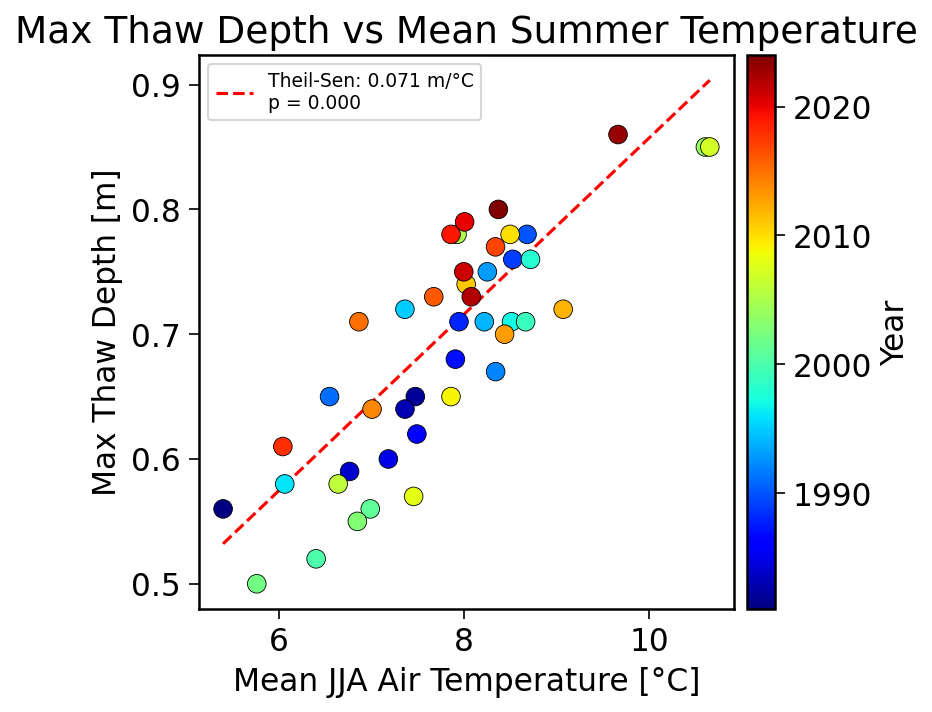

In [38]:
obs_temp = runobs_transect_1981_2024.copy()
obs_temp['Date']  = pd.to_datetime(obs_temp['Date'])
obs_temp['year']  = obs_temp['Date'].dt.year
obs_temp['month'] = obs_temp['Date'].dt.month
jja_temp = (obs_temp[obs_temp['month'].between(6, 8)]
            .groupby('year')['air temperature [K]'].mean()
            .reset_index().rename(columns={'air temperature [K]': 'jja_temp_K'}))
jja_temp['jja_temp_C'] = jja_temp['jja_temp_K'] - 273.15

merged_thaw = max_thaw.merge(jja_temp, on='year').dropna()
temp_m   = merged_thaw['jja_temp_C'].values
depths_m = merged_thaw['max_thaw_depth'].values
ts_jja = theilslopes(depths_m, temp_m)
tau_jja, p_jja = kendalltau(temp_m, depths_m)
x_line = np.linspace(temp_m.min(), temp_m.max(), 200)

fig, ax = plt.subplots(figsize=(6, 5), dpi=150)
sc = ax.scatter(temp_m, depths_m, c=merged_thaw['year'].values, cmap='jet',
                vmin=years_ts.min(), vmax=years_ts.max(),
                s=80, edgecolors='k', linewidths=0.4, zorder=3)
ax.plot(x_line, ts_jja.slope * x_line + ts_jja.intercept, '--', color='red', lw=1.5,
        label=f'Theil-Sen: {ts_jja.slope:.3f} m/°C\np = {p_jja:.3f}')
ax.set_xlabel('Mean JJA Air Temperature [°C]'); ax.set_ylabel('Max Thaw Depth [m]')
ax.set_title('Max Thaw Depth vs Mean Summer Temperature'); ax.legend(fontsize=9)
fig.colorbar(sc, ax=ax, pad=0.02, label='Year'); plt.tight_layout(); plt.show()

## 10. Net Runoff Trends (1981–2024)

Yearly cumulative net runoff is computed from the transect observation files (column `net runoff [mol/d]`), converted to m³/yr using the molar volume of water (1 mol H₂O = 1.8015×10⁻⁵ m³). A Theil–Sen trend and Mann–Kendall test are applied.

/tmp/ipykernel_1880699/2956261005.py:6: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  yearly_runoff = (obs_ro['net runoff [mol/d]'] * MOL_TO_M3).resample('Y').sum()


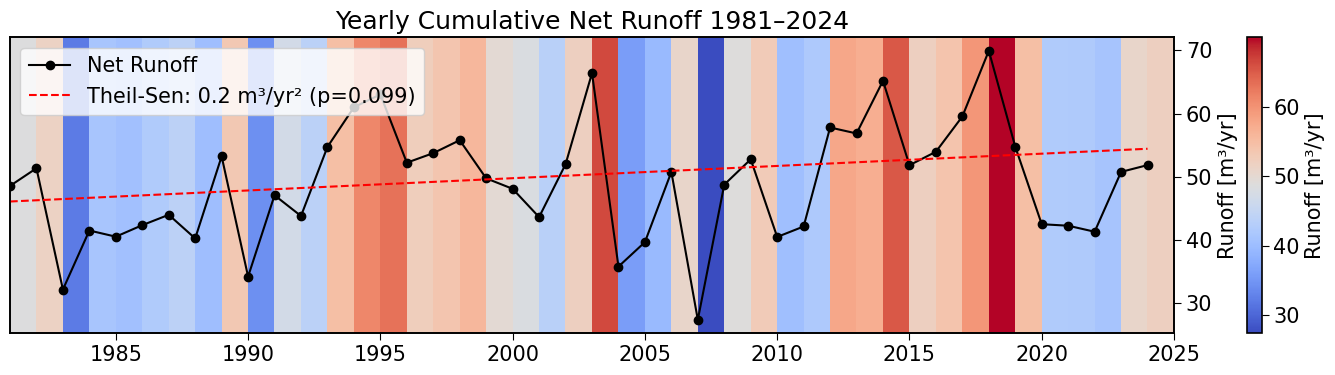

In [39]:
MOL_TO_M3 = 18.015e-6   # 1 mol H₂O → m³

obs_ro = runobs_transect_1981_2024.copy()
obs_ro['Date'] = pd.to_datetime(obs_ro['Date'])
obs_ro = obs_ro.set_index('Date')
yearly_runoff = (obs_ro['net runoff [mol/d]'] * MOL_TO_M3).resample('Y').sum()
ro_years = yearly_runoff.index.year.values
ro_vals  = yearly_runoff.values

ts_ro  = theilslopes(ro_vals, ro_years)
mk_ro  = mk.original_test(ro_vals)
trend_ro = ts_ro.slope * ro_years + ts_ro.intercept

fig, ax1 = plt.subplots(figsize=(15, 4))
ax1.imshow(ro_vals.reshape(1, -1), aspect='auto', cmap='coolwarm',
           extent=[ro_years[0], 2025, 0, 1],
           vmin=np.nanmin(ro_vals), vmax=np.nanmax(ro_vals))
ax1.set_yticks([]); ax1.set_xlim(ro_years[0], 2025)
ax1.set_title('Yearly Cumulative Net Runoff 1981–2024')
plt.colorbar(ax1.images[0], ax=ax1, orientation='vertical').set_label('Runoff [m³/yr]')
ax2 = ax1.twinx()
ax2.plot(ro_years, ro_vals, marker='o', linestyle='-', color='black', label='Net Runoff')
ax2.plot(ro_years, trend_ro, linestyle='--', color='red',
         label=f'Theil-Sen: {ts_ro.slope:.1f} m³/yr² (p={mk_ro.p:.3f})')
ax2.set_ylabel('Runoff [m³/yr]'); ax2.set_xlim(ro_years[0], 2025)
ax2.legend(loc='upper left'); ax2.grid(False)
plt.tight_layout(); plt.show()

### 10b. Runoff vs Winter Temperature and Snowfall

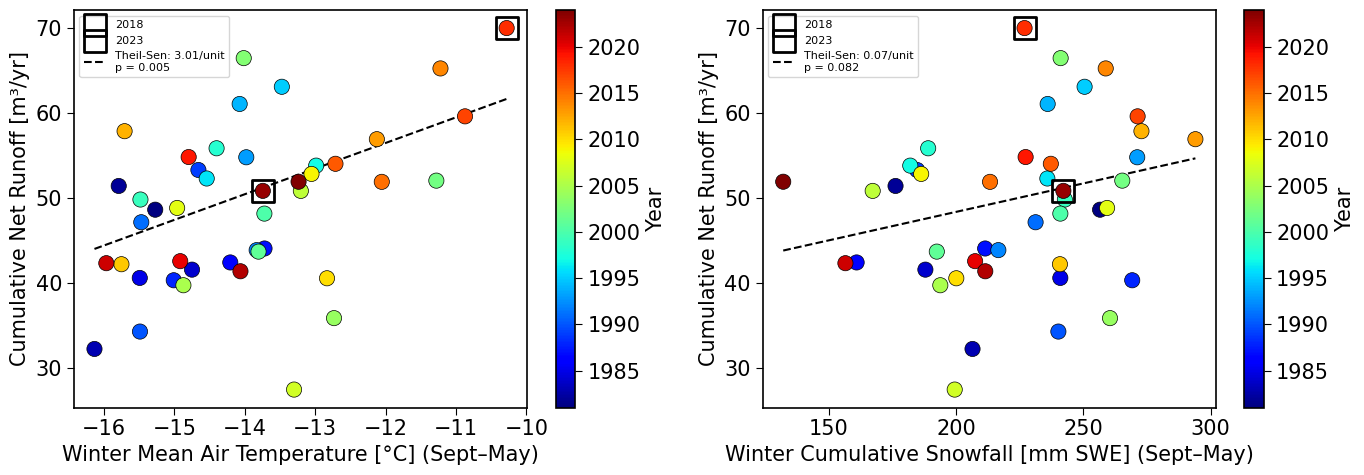

In [40]:
ro_df   = pd.DataFrame({'year': ro_years, 'runoff_m3': ro_vals})
wt_ro   = compute_winter_temp(df_combined, ro_years)
ws_ro   = compute_winter_snow(df_combined, ro_years)
merged_ro = ro_df.merge(wt_ro, on='year').merge(ws_ro, on='year').dropna()
years_ro = merged_ro['year'].values
ro_m   = merged_ro['runoff_m3'].values
temp_ro = merged_ro['winter_temp'].values
snow_ro = merged_ro['snowfall'].values

fig, (ax_t, ax_s) = plt.subplots(1, 2, figsize=(14, 5))
for ax, x, xlabel in [
    (ax_t, temp_ro, 'Winter Mean Air Temperature [°C] (Sept–May)'),
    (ax_s, snow_ro, 'Winter Cumulative Snowfall [mm SWE] (Sept–May)'),
]:
    sc = ax.scatter(x, ro_m, c=years_ro, cmap='jet', vmin=1981, vmax=2024,
                    s=120, edgecolors='black', linewidths=0.5, zorder=3)
    for hy in [2018, 2023]:
        msk = years_ro == hy
        ax.scatter(x[msk], ro_m[msk], marker='s', s=250,
                   facecolors='none', edgecolors='black', linewidths=2, zorder=5, label=str(hy))
    ts_sc = theilslopes(ro_m, x)
    tau_ro, p_ro = kendalltau(ro_m, x)
    x_line = np.linspace(x.min(), x.max(), 200)
    ax.plot(x_line, ts_sc.slope * x_line + ts_sc.intercept, '--', color='k', linewidth=1.5,
            label=f'Theil-Sen: {ts_sc.slope:.2f}/unit\np = {p_ro:.3f}')
    ax.set_xlabel(xlabel); ax.set_ylabel('Cumulative Net Runoff [m³/yr]')
    ax.legend(fontsize=8); plt.colorbar(sc, ax=ax, label='Year')
plt.tight_layout(); plt.show()

## 11. Domain-Averaged Enthalpy Analysis

Domain-averaged enthalpy captures the total thermal energy of the subsurface column. The enthalpy time series was pre-computed and saved to CSV (`max_summer_enthalpy_1981_2024.csv`). The commented block below shows how it was originally computed from the VisFiles.

> **Pre-requisite:** `max_summer_enthalpy_1981_2024.csv` must exist in the working directory. This file contains the yearly maximum summer (JJA) domain-averaged enthalpy [J/mol].

In [42]:
# ── Commented: original enthalpy computation from VisFiles (slow) ─────────────
# def compute_enthalpy_series(vis, epoch):
#     records = []
#     total_volume = sum(vis.get("cell_volume", vis.cycles[0]))
#     for n, cyc in enumerate(vis.cycles):
#         e = vis.get("enthalpy", cyc)
#         V = vis.get("cell_volume", cyc)
#         enthalpy_mean = (e * V).sum() / total_volume * 1e6   # J/mol
#         date = epoch + timedelta(days=float(vis.times[n]))
#         records.append({'Date': date, 'time [d]': vis.times[n],
#                         'enthalpy_mean[J/mol]': enthalpy_mean})
#     return pd.DataFrame(records)
#
# df_enth_s1 = compute_enthalpy_series(vis_1981_2020, EPOCH_1981)
# df_enth_s1 = df_enth_s1[pd.to_datetime(df_enth_s1['Date']) < CUTOFF_DATE]
# df_enth_s2 = compute_enthalpy_series(vis_2019_2024, EPOCH_2019)
# df_enth_s2 = df_enth_s2[pd.to_datetime(df_enth_s2['Date']) >= CUTOFF_DATE]
# df_enth = (pd.concat([df_enth_s1, df_enth_s2])
#            .drop_duplicates('Date').sort_values('Date').reset_index(drop=True))
# df_enth['Date']  = pd.to_datetime(df_enth['Date'])
# df_enth['year']  = df_enth['Date'].dt.year
# df_enth['month'] = df_enth['Date'].dt.month
# df_summer_enth   = df_enth[df_enth['month'].between(6, 8)]
# idx_max          = df_summer_enth.groupby('year')['enthalpy_mean[J/mol]'].idxmax()
# df_max_enthalpy  = df_summer_enth.loc[idx_max, ['Date','year','enthalpy_mean[J/mol]']].sort_values('year').reset_index(drop=True)
# df_max_enthalpy.to_csv("max_summer_enthalpy_1981_2024.csv", index=False)

# ── Load from CSV ──────────────────────────────────────────────────────────────
df_max_enthalpy = pd.read_csv("../data/max_summer_enthalpy_1981_2024.csv")
enth_years = df_max_enthalpy['year'].values
enth_vals  = df_max_enthalpy['enthalpy_mean[J/mol]'].values
print(f"Enthalpy data loaded: {enth_years[0]}–{enth_years[-1]}, {len(enth_years)} years")

Enthalpy data loaded: 1981–2024, 44 years


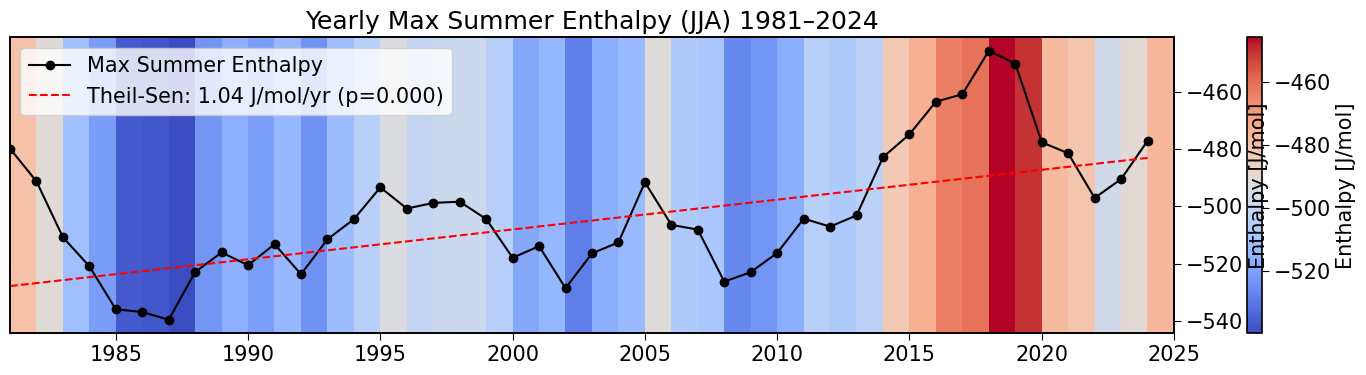

In [43]:
ts_en  = theilslopes(enth_vals, enth_years)
mk_en  = mk.original_test(enth_vals)
trend_en = ts_en.slope * enth_years + ts_en.intercept

fig, ax1 = plt.subplots(figsize=(15, 4))
ax1.imshow(enth_vals.reshape(1, -1), aspect='auto', cmap='coolwarm',
           extent=[enth_years[0], 2025, 0, 1],
           vmin=np.nanmin(enth_vals), vmax=np.nanmax(enth_vals))
ax1.set_yticks([]); ax1.set_xlim(enth_years[0], 2025)
ax1.set_title('Yearly Max Summer Enthalpy (JJA) 1981–2024')
plt.colorbar(ax1.images[0], ax=ax1, orientation='vertical').set_label('Enthalpy [J/mol]')
ax2 = ax1.twinx()
ax2.plot(enth_years, enth_vals, marker='o', linestyle='-', color='black', label='Max Summer Enthalpy')
ax2.plot(enth_years, trend_en, linestyle='--', color='red',
         label=f'Theil-Sen: {ts_en.slope:.2f} J/mol/yr (p={mk_en.p:.3f})')
ax2.set_ylabel('Enthalpy [J/mol]'); ax2.set_xlim(enth_years[0], 2025)
ax2.legend(loc='upper left'); ax2.grid(False)
plt.tight_layout(); plt.show()

### 11b. Enthalpy vs Zero-Curtain Metrics

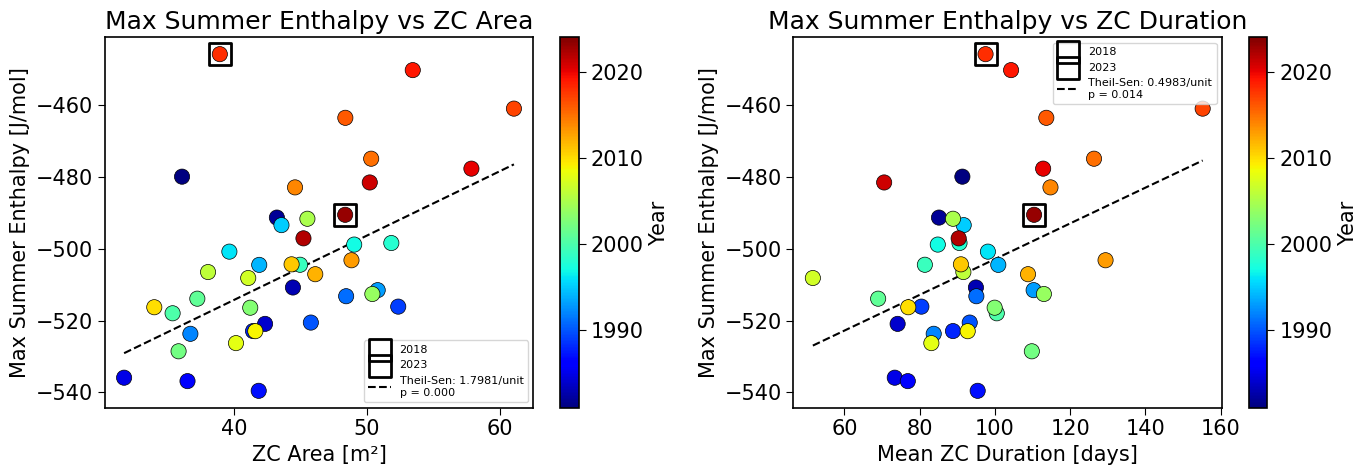

In [44]:
merged_en = df_max_enthalpy.merge(
    df_zc[['year','mean_zc_duration_days','avg_ZC_area_m2']].reset_index(drop=True), on='year'
).dropna()
years_en = merged_en['year'].values
enth_m   = merged_en['enthalpy_mean[J/mol]'].values
zc_dur_m = merged_en['mean_zc_duration_days'].values
zc_area_m = merged_en['avg_ZC_area_m2'].values

fig, (ax_a, ax_d) = plt.subplots(1, 2, figsize=(14, 5))
for ax, y_data, ylabel, tag in [
    (ax_a, zc_area_m, 'ZC Area [m²]',          'ZC Area'),
    (ax_d, zc_dur_m,  'Mean ZC Duration [days]', 'ZC Duration'),
]:
    sc = ax.scatter(y_data, enth_m, c=years_en, cmap='jet', vmin=1981, vmax=2024,
                    s=120, edgecolors='black', linewidths=0.5, zorder=3)
    for hy in [2018, 2023]:
        msk = years_en == hy
        ax.scatter(y_data[msk], enth_m[msk], marker='s', s=250,
                   facecolors='none', edgecolors='black', linewidths=2, zorder=5, label=str(hy))
    ts_sc = theilslopes(enth_m, y_data)
    tau_ec, p_ec = kendalltau(y_data, enth_m)
    x_line = np.linspace(y_data.min(), y_data.max(), 200)
    ax.plot(x_line, ts_sc.slope * x_line + ts_sc.intercept, '--', color='k', linewidth=1.5,
            label=f'Theil-Sen: {ts_sc.slope:.4f}/unit\np = {p_ec:.3f}')
    ax.set_xlabel(ylabel); ax.set_ylabel('Max Summer Enthalpy [J/mol]')
    ax.set_title(f'Max Summer Enthalpy vs {tag}'); ax.legend(fontsize=8)
    plt.colorbar(sc, ax=ax, label='Year')
plt.tight_layout(); plt.show()

## 12. Velocity Field Visualization (2019 Seasonal Snapshots)

Darcy velocity magnitude (log₁₀-scaled, cm/day) is shown for five dates spanning the 2019 thaw season. Arrows indicate flow direction (unit vectors). The transect is displayed with a vertical exaggeration of 12× to resolve the shallow active layer.

In [45]:
# ── Reload 1981–2020 transect VisFile for velocity extraction ────────────────
# (using single-day stride for velocity field snapshots)
rundir_vel = "../../run/transect_spinup_imnavait_ws_1981_2020_ABoVE_DAAC_snow_rain_albdo"
vis_vel = ats_xdmf.VisFile(rundir_vel, time_unit='d')
vis_vel.filterIndices(range(0, min(len(vis_vel.cycles), int(vis_vel.times[-1])), 1))
vis_vel.loadMeshPolygons()

vis_surf_vel = ats_xdmf.VisFile(rundir_vel, domain='surface', time_unit='d')
vis_surf_vel.filterIndices(range(0, min(len(vis_vel.cycles), int(vis_vel.times[-1])), 1))
vis_surf_vel.loadMesh(order=['x', 'z'])

year_start_vel = datetime(1981, 1, 1)
elev_vel = vis_surf_vel.get('surface-elevation', vis_surf_vel.cycles[0])
dx_vel   = 1.0092592592592524
n_cells_vel = len(elev_vel)
x_surf_vel  = np.arange(n_cells_vel) * dx_vel

/tmp/ipykernel_1880699/1579129842.py:16: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_vel = plt.cm.get_cmap('turbo').copy()


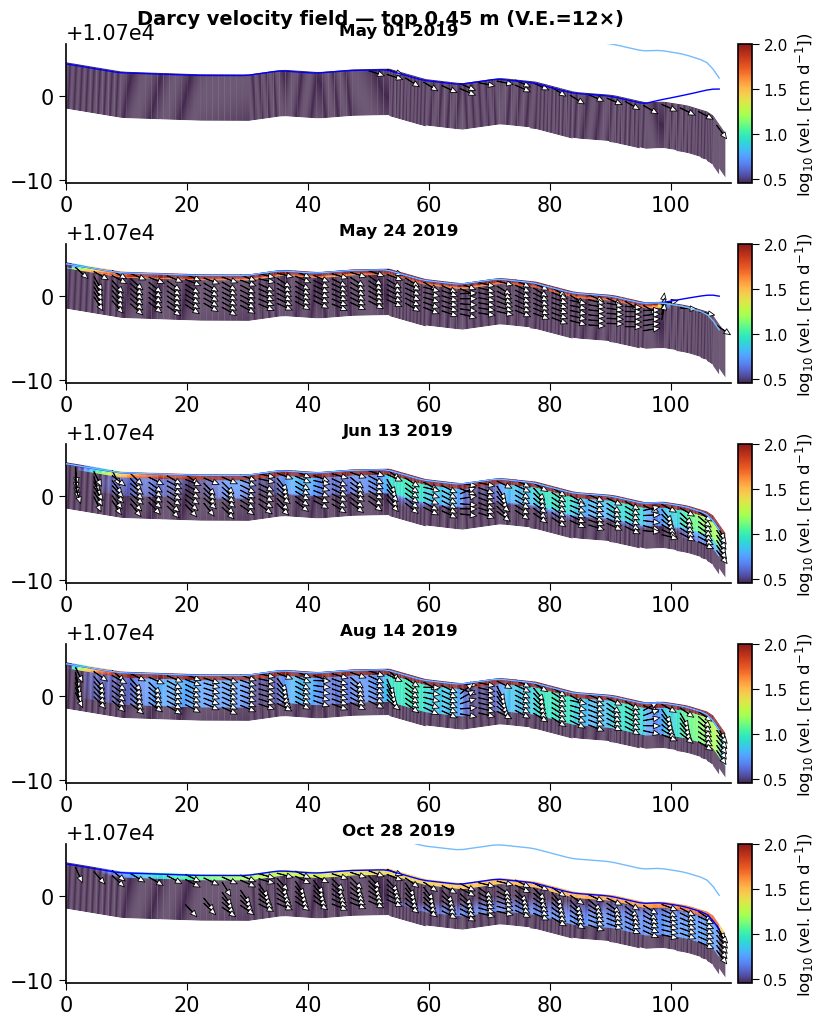

In [46]:
target_dates = {
    "May 01 2019":  datetime(2019, 5,  1),
    "May 24 2019":  datetime(2019, 5, 24),
    "Jun 13 2019":  datetime(2019, 6, 13),
    "Aug 14 2019":  datetime(2019, 8, 14),
    "Oct 28 2019":  datetime(2019, 10, 28),
}

depth_limit           = 0.45
threshold             = np.log10(0.8)
vertical_exaggeration = 12
slope_ve  = np.polyfit(x_surf_vel, elev_vel, 1)[0]
shear_ve  = -slope_ve * (vertical_exaggeration - 1) * 0.93
z_surf_affine = vertical_exaggeration * elev_vel + shear_ve * x_surf_vel

cmap_vel = plt.cm.get_cmap('turbo').copy()
cmap_vel.set_bad('white')

fig, axes = plt.subplots(nrows=len(target_dates), ncols=1, figsize=(7.5, 10), constrained_layout=True)

for ax, (label, target) in zip(axes, target_dates.items()):
    n = (target - year_start_vel).days
    vx = vis_vel.get("darcy_velocity.0", vis_vel.cycles[n])
    vz = vis_vel.get("darcy_velocity.2", vis_vel.cycles[n])

    poly_raw  = vis_vel.getMeshPolygons(cmap='turbo')
    centroids = np.array([p.vertices.mean(axis=0) for p in poly_raw.get_paths()])
    vmag      = np.sqrt(vx**2 + vz**2)
    vmag_log  = np.log10(vmag * 100 * 86400.0 + 1e-10)

    surface_z         = np.interp(centroids[:, 0], x_surf_vel, elev_vel)
    depth_below       = surface_z - centroids[:, 1]
    vmag_log_masked   = np.ma.array(vmag_log, mask=depth_below > depth_limit)

    x_unique = np.unique(np.round(centroids[:, 0], 2))
    z_unique = np.unique(np.round(centroids[:, 1], 2))
    sub_mask = np.zeros(len(centroids), dtype=bool)
    for i, (cx, cz) in enumerate(centroids):
        xi = np.argmin(np.abs(x_unique - cx)); zi = np.argmin(np.abs(z_unique - cz))
        if xi % 3 == 0 and zi % 5 == 0:
            sub_mask[i] = True

    c_sub   = centroids[sub_mask]; vx_sub = vx[sub_mask]; vz_sub = vz[sub_mask]
    vm_sub  = np.sqrt(vx_sub**2 + vz_sub**2); vm_sub[vm_sub == 0] = 1.0
    vu_x    = vx_sub / vm_sub; vu_z = vz_sub / vm_sub
    vm_log_sub = np.log10(vm_sub * 100 * 86400.0 + 1e-10)
    sz_sub     = np.interp(c_sub[:, 0], x_surf_vel, elev_vel)
    db_sub     = sz_sub - c_sub[:, 1]
    arrow_mask = (vm_log_sub >= threshold) & (db_sub <= depth_limit)
    c_q = c_sub[arrow_mask]; vux_q = vu_x[arrow_mask]; vuz_q = vu_z[arrow_mask]

    xq_plot  = c_q[:, 0]
    zq_affine = vertical_exaggeration * c_q[:, 1] + shear_ve * c_q[:, 0]
    vx_t  = vux_q + shear_ve * vuz_q; vz_t = vertical_exaggeration * vuz_q
    vmag_t = np.sqrt(vx_t**2 + vz_t**2); vmag_t[vmag_t == 0] = 1.0
    vx_t /= vmag_t; vz_t /= vmag_t

    orig_polys = vis_vel.getMeshPolygons(cmap='turbo', linewidth=0).get_paths()
    trans_verts = []
    for pp in orig_polys:
        v = pp.vertices.copy()
        v[:, 1] = vertical_exaggeration * v[:, 1] + shear_ve * v[:, 0]
        trans_verts.append(v)

    poly_t = PolyCollection(trans_verts, cmap=cmap_vel, linewidth=0)
    poly_t.set_array(vmag_log_masked); poly_t.set_clim(0.45, 2.0); poly_t.set_alpha(0.9)
    ax.add_collection(poly_t)

    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="2%", pad=0.07)
    cb  = plt.colorbar(poly_t, cax=cax)
    cb.ax.tick_params(labelsize=11)
    cb.set_label(r"$\log_{10}$(vel. [cm d$^{-1}$])", fontsize=12)

    ax.quiver(xq_plot, zq_affine, vx_t, vz_t, angles='xy', scale=40, width=0.0007,
              headwidth=12, headlength=14, headaxislength=14,
              facecolors='white', edgecolors='black', linewidth=0.6, alpha=1.0, zorder=5)

    pd_surf   = vis_surf_vel.get('surface-ponded_depth', vis_surf_vel.cycles[n])
    snowdepth = vis_surf_vel.get('snow-depth',           vis_surf_vel.cycles[n])
    ax.plot(x_surf_vel, z_surf_affine + vertical_exaggeration * pd_surf,
            'b', linewidth=1, label='Ponded depth', zorder=15)
    ax.plot(x_surf_vel, z_surf_affine + vertical_exaggeration * snowdepth,
            color='#75bbfd', linewidth=1, label='Snow depth', zorder=15)

    pad_below = vertical_exaggeration * (depth_limit + 0.08)
    pad_above = vertical_exaggeration * 0.2
    ax.set_xlim(0, 110)
    ax.set_ylim(z_surf_affine.min() - pad_below, z_surf_affine.max() + pad_above)
    ax.set_title(label, fontsize=12, fontweight='bold')
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

plt.suptitle(f"Darcy velocity field — top {depth_limit} m (V.E.={vertical_exaggeration}×)",
             fontsize=14, fontweight='bold', y=1.01)
plt.show()
